## Imports

In [1]:
import os
import imageio
import albumentations as A
import random
import numpy as np
import nibabel as nib
import multiprocessing as mp
import matplotlib.pyplot as plt
import numpy as np
import pytorch_lightning as pl
import pandas as pd
import SimpleITK as sitk
import torch
import monai
import shutil
import subprocess
import importlib.util
import torch.nn as nn
import torch.nn.functional as F
import time
from math import nan
from typing import List, Dict, Union
from glob import iglob, glob
from tqdm import tqdm
from argparse import Namespace
from torch import nn, Tensor
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.optim import SGD
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torchvision.transforms import Compose
from typing import Tuple
from pytorch_lightning import LightningDataModule
from pytorch_lightning.callbacks import ModelCheckpoint, LearningRateMonitor, TQDMProgressBar
from pytorch_lightning.loggers import CSVLogger
from pathlib import Path
from sklearn.model_selection import train_test_split
from monai.transforms import NormalizeIntensity
from scipy.ndimage import binary_erosion, distance_transform_edt, label as connected_components
from importlib.metadata import version
from nibabel.processing import resample_from_to
from transformers import AutoTokenizer, AutoModel

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print("GPU:", torch.cuda.get_device_name(0))

CUDA disponível: True
GPU: NVIDIA GeForce RTX 3060


In [3]:
# Check libraries version
print(f"PyTorch version: {torch.__version__}")
print(f"Pytorch Lightning version: {pl.__version__}")

PyTorch version: 2.5.1+cu121
Pytorch Lightning version: 2.6.6


## Download e Análise do Dataset



**Exames:**
* ad -> Alzheimer's Disease (doença de Alzheimer)
* cn -> Cognitively Normal (indivíduos cognitivamente normais)
* mci -> Mild Cognitive Impairment (comprometimento cognitivo leve)

**Máscaras divididas em:**
* Esquerda (L)
* Direita (R)
* Bilateral (all)



In [4]:
harp_path = "/mnt/nas/silvana"

print(os.listdir(harp_path))

['@Recently-Snapshot', 'samples', 'masks', '.Trash-1007', 'baseline_unet_3d', 'baseline_nnunet']


In [5]:
print(os.listdir(harp_path + "/samples"))
print(os.listdir(harp_path + "/samples/ad"))
print(os.listdir(harp_path + "/samples/cn"))
print(os.listdir(harp_path + "/samples/mci"))

['ad', 'cn', 'mci']
['e2dhipseg_masks', '002_S_0816.nii.gz', '002_S_0938.nii.gz', '003_S_1059.nii.gz', '003_S_1257.nii.gz', '003_S_4136.nii.gz', '003_S_4142.nii.gz', '005_S_0221.nii.gz', '005_S_1341.nii.gz', '006_S_4192.nii.gz', '007_S_1304.nii.gz', '009_S_1334.nii.gz', '011_S_0010.nii.gz', '011_S_0183.nii.gz', '012_S_0689.nii.gz', '013_S_0592.nii.gz', '016_S_0991.nii.gz', '016_S_1263.nii.gz', '018_S_4696.nii.gz', '019_S_4252.nii.gz', '019_S_4549.nii.gz', '020_S_0213.nii.gz', '023_S_0139.nii.gz', '023_S_0916.nii.gz', '023_S_1289.nii.gz', '027_S_1081.nii.gz', '027_S_1385.nii.gz', '031_S_1209.nii.gz', '067_S_0812.nii.gz', '067_S_1185.nii.gz', '067_S_1253.nii.gz', '082_S_1079.nii.gz', '094_S_4089.nii.gz', '098_S_0149.nii.gz', '100_S_1062.nii.gz', '123_S_0088.nii.gz', '123_S_0091.nii.gz', '123_S_0094.nii.gz', '123_S_0162.nii.gz', '126_S_0606.nii.gz', '126_S_0784.nii.gz', '127_S_0754.nii.gz', '127_S_0844.nii.gz', '130_S_0956.nii.gz', '130_S_4730.nii.gz', '131_S_0691.nii.gz']
['e2dhipseg_mas

In [6]:
print(os.listdir(harp_path + "/masks"))
print(os.listdir(harp_path + "/masks/ad"))
print(os.listdir(harp_path + "/masks/all"))
print(os.listdir(harp_path + "/masks/cn"))
print(os.listdir(harp_path + "/masks/mci"))

['ad', 'all', 'cn', 'mci', 'check_class_harp.py', 'all_aligned', 'multiclass_aligned', 'labels_backups']
['002_S_0816_L.nii.gz', '002_S_0816_R.nii.gz', '002_S_0938_L.nii.gz', '002_S_0938_R.nii.gz', '003_S_1059_L.nii.gz', '003_S_1059_R.nii.gz', '003_S_1257_L.nii.gz', '003_S_1257_R.nii.gz', '003_S_4136_L.nii.gz', '003_S_4136_R.nii.gz', '003_S_4142_L.nii.gz', '003_S_4142_R.nii.gz', '005_S_0221_L.nii.gz', '005_S_0221_R.nii.gz', '005_S_1341_L.nii.gz', '005_S_1341_R.nii.gz', '006_S_4192_L.nii.gz', '006_S_4192_R.nii.gz', '007_S_1304_L.nii.gz', '007_S_1304_R.nii.gz', '009_S_1334_L.nii.gz', '009_S_1334_R.nii.gz', '011_S_0010_L.nii.gz', '011_S_0010_R.nii.gz', '011_S_0183_L.nii.gz', '011_S_0183_R.nii.gz', '012_S_0689_L.nii.gz', '012_S_0689_R.nii.gz', '013_S_0592_L.nii.gz', '013_S_0592_R.nii.gz', '016_S_0991_L.nii.gz', '016_S_0991_R.nii.gz', '016_S_1263_L.nii.gz', '016_S_1263_R.nii.gz', '018_S_4696_L.nii.gz', '018_S_4696_R.nii.gz', '019_S_4252_L.nii.gz', '019_S_4252_R.nii.gz', '019_S_4549_L.nii.gz

In [7]:
harp_path = Path("/mnt/nas/silvana/")

pastas = [
    "samples/ad",
    "samples/cn",
    "samples/mci",
    "masks/ad",
    "masks/cn",
    "masks/mci",
    "masks/all"
]

for pasta in pastas:
    caminho = harp_path / pasta

    arquivos = [f for f in caminho.iterdir() if f.is_file()]

    print(f"\n{pasta}")
    print("Quantidade de arquivos:", len(arquivos))

    for arquivo in arquivos[:5]:
        print("  ", arquivo.name)


samples/ad
Quantidade de arquivos: 45
   002_S_0816.nii.gz
   002_S_0938.nii.gz
   003_S_1059.nii.gz
   003_S_1257.nii.gz
   003_S_4136.nii.gz

samples/cn
Quantidade de arquivos: 44
   002_S_0295.nii.gz
   002_S_0413.nii.gz
   002_S_0559.nii.gz
   002_S_0685.nii.gz
   002_S_1261.nii.gz

samples/mci
Quantidade de arquivos: 46
   002_S_0729.nii.gz
   002_S_0782.nii.gz
   002_S_0954.nii.gz
   002_S_1070.nii.gz
   002_S_1155.nii.gz

masks/ad
Quantidade de arquivos: 90
   002_S_0816_L.nii.gz
   002_S_0816_R.nii.gz
   002_S_0938_L.nii.gz
   002_S_0938_R.nii.gz
   003_S_1059_L.nii.gz

masks/cn
Quantidade de arquivos: 88
   002_S_0295_L.nii.gz
   002_S_0295_R.nii.gz
   002_S_0413_L.nii.gz
   002_S_0413_R.nii.gz
   002_S_0559_L.nii.gz

masks/mci
Quantidade de arquivos: 92
   002_S_0729_L.nii.gz
   002_S_0729_R.nii.gz
   002_S_0782_L.nii.gz
   002_S_0782_R.nii.gz
   002_S_0954_L.nii.gz

masks/all
Quantidade de arquivos: 135
   002_S_0295.nii.gz
   002_S_0413.nii.gz
   002_S_0559.nii.gz
   002_S

In [8]:
ids = set()

for grupo in ["ad", "cn", "mci"]:
    pasta = harp_path / "samples" / grupo

    for arquivo in pasta.glob("*.nii.gz"):
        ids.add(arquivo.name.replace(".nii.gz", ""))

print("Total de identificadores únicos:", len(ids))

Total de identificadores únicos: 135


In [9]:
for grupo in ["ad", "cn", "mci"]:

    samples = harp_path / "samples" / grupo
    masks = harp_path / "masks" / grupo

    imagens = {f.name.replace(".nii.gz", ""): f
               for f in samples.glob("*.nii.gz")}

    mascaras_L = {f.name.replace("_L.nii.gz", ""): f
                  for f in masks.glob("*_L.nii.gz")}

    mascaras_R = {f.name.replace("_R.nii.gz", ""): f
                  for f in masks.glob("*_R.nii.gz")}

    ids_imagens = set(imagens)
    ids_L = set(mascaras_L)
    ids_R = set(mascaras_R)

    print(f"\n==== GRUPO {grupo.upper()} =====")
    print("Imagens:", len(ids_imagens))
    print("Máscaras L:", len(ids_L))
    print("Máscaras R:", len(ids_R))

    print("Sem máscara esquerda:", ids_imagens - ids_L)
    print("Sem máscara direita:", ids_imagens - ids_R)
    print("Máscaras sem imagem:", (ids_L | ids_R) - ids_imagens)


==== GRUPO AD =====
Imagens: 45
Máscaras L: 45
Máscaras R: 45
Sem máscara esquerda: set()
Sem máscara direita: set()
Máscaras sem imagem: set()

==== GRUPO CN =====
Imagens: 44
Máscaras L: 44
Máscaras R: 44
Sem máscara esquerda: set()
Sem máscara direita: set()
Máscaras sem imagem: set()

==== GRUPO MCI =====
Imagens: 46
Máscaras L: 46
Máscaras R: 46
Sem máscara esquerda: set()
Sem máscara direita: set()
Máscaras sem imagem: set()


In [10]:
grupo = "cn"
participante = "002_S_0295"

imagem = nib.load(f"/mnt/nas/silvana/samples/{grupo}/{participante}.nii.gz")

mask_L = nib.load(f"/mnt/nas/silvana/masks/{grupo}/{participante}_L.nii.gz")

mask_R = nib.load(f"/mnt/nas/silvana/masks/{grupo}/{participante}_R.nii.gz")

mask_all = nib.load(f"/mnt/nas/silvana/masks/all/{participante}.nii.gz")

arquivos = {
    "Imagem T1": imagem,
    "Máscara esquerda": mask_L,
    "Máscara direita": mask_R,
    "Máscara bilateral": mask_all
}

for nome, arquivo in arquivos.items():

    dados = arquivo.get_fdata()

    print(f"\n{nome}")
    print("Dimensões:", dados.shape)
    print("Espaçamento:", arquivo.header.get_zooms())
    print("Orientação:", nib.aff2axcodes(arquivo.affine))
    print("Valores únicos:", np.unique(dados))

    print(
        "Alinhamento com imagem:",
        np.allclose(arquivo.affine, imagem.affine)
    )


Imagem T1
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('R', 'A', 'S')
Valores únicos: [0.0000e+00 1.0000e+00 2.0000e+00 ... 1.6667e+04 1.6695e+04 1.7004e+04]
Alinhamento com imagem: True

Máscara esquerda
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('R', 'A', 'S')
Valores únicos: [0. 1.]
Alinhamento com imagem: True

Máscara direita
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('R', 'A', 'S')
Valores únicos: [0. 1.]
Alinhamento com imagem: True

Máscara bilateral
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('L', 'A', 'S')
Valores únicos: [0. 1.]
Alinhamento com imagem: False


In [11]:
# Diretório de saída
pasta_saida = harp_path / "masks" / "multiclass_aligned"
pasta_saida.mkdir(exist_ok=True)

grupos = ["ad", "cn", "mci"]

# Contadores
total = 0
sucesso = 0
erros = []
resultados = []

for grupo in grupos:
    pasta_imagens = harp_path / "samples" / grupo

    for imagem_path in sorted(pasta_imagens.glob("*.nii.gz")):
        id_paciente = imagem_path.name.replace(".nii.gz", "")
        mascara_path = harp_path / "masks" / "all" / f"{id_paciente}.nii.gz"
        total += 1

        try:
            # Localizar as máscaras individuais
            mascara_L_path = None
            mascara_R_path = None
            grupo_mascara = None

            for g in grupos:

                caminho_L = harp_path / "masks" / g / f"{id_paciente}_L.nii.gz"
                caminho_R = harp_path / "masks" / g / f"{id_paciente}_R.nii.gz"

                if caminho_L.exists() and caminho_R.exists():
                    mascara_L_path = caminho_L
                    mascara_R_path = caminho_R
                    grupo_mascara = g
                    break

            if mascara_L_path is None:
                raise FileNotFoundError(f"Máscaras esquerda não encontradas para {id_paciente}")

            if mascara_R_path is None:
                raise FileNotFoundError(f"Máscara direita não encontrada para {id_paciente}")

            # Carregar imagem T1
            imagem = nib.load(str(imagem_path))

            # Carregar máscaras individuais
            mascara_L = nib.load(str(mascara_L_path))
            mascara_R = nib.load(str(mascara_R_path))

            # Alinhar cada máscara ao espaço da imagem T1
            L_alinhada = resample_from_to(mascara_L, (imagem.shape, imagem.affine), order=0)

            R_alinhada = resample_from_to(mascara_R, (imagem.shape, imagem.affine), order=0)

            # Converter cada máscara em binária
            dados_L = L_alinhada.get_fdata() > 0.5
            dados_R = R_alinhada.get_fdata() > 0.5

            # Verificar máscaras vazias
            if not dados_L.any():
                raise ValueError("Máscara esquerda vazia")

            if not dados_R.any():
                raise ValueError("Máscara direita vazia")

            # Verificar sobreposição entre os lados
            sobreposicao = np.logical_and(dados_L, dados_R)

            if sobreposicao.any():
                raise ValueError(f"Sobreposição entre L e R: {sobreposicao.sum()} voxels")

            # Construir máscara multiclasse
            dados = np.zeros(imagem.shape, dtype=np.uint8)

            dados[dados_L] = 1
            dados[dados_R] = 2

            # Criar NIfTI
            header = imagem.header.copy()
            header.set_data_dtype(np.uint8)

            mascara_multiclasse = nib.Nifti1Image(
                dados,
                imagem.affine,
                header
            )

            # Salvar
            saida = pasta_saida / f"{id_paciente}.nii.gz"
            nib.save(mascara_multiclasse, str(saida))

            # Verificações
            dimensoes_ok = mascara_multiclasse.shape == imagem.shape

            assert mascara_multiclasse.shape == imagem.shape

            affine_ok = np.allclose(mascara_multiclasse.affine, imagem.affine)

            assert np.allclose(mascara_multiclasse.affine, imagem.affine)

            orientacao_ok = (nib.aff2axcodes(mascara_multiclasse.affine) == nib.aff2axcodes(imagem.affine))

            if not all([
                dimensoes_ok,
                affine_ok,
                orientacao_ok
            ]):
                raise ValueError("Falha na verificação geométrica ou binária")

            valores = np.unique(dados)
            
            assert set(valores).issubset({0, 1, 2})
            assert 0 in valores and 1 in valores and 2 in valores

            sucesso += 1

            resultados.append({
                "ID": id_paciente,
                "Grupo": grupo.upper(),
                "Grupo das máscaras": grupo_mascara.upper(),
                "Dimensões": dimensoes_ok,
                "Affine": affine_ok,
                "Orientação": orientacao_ok,
                "Voxels L": int(dados_L.sum()),
                "Voxels R": int(dados_R.sum()),
                "Valores": valores.tolist(),
                "Status": "OK"
            })

        except Exception as e:

            erros.append({
                "ID": id_paciente,
                "Grupo": grupo.upper(),
                "Erro": str(e)
            })

            print(f"ERRO - {id_paciente}: {e}")

print("\n==== RESULTADO ====")
print("Total de exames:", total)
print("Sucesso:", sucesso)
print("Falhas:", len(erros))
print("Pasta de saída:", pasta_saida)


==== RESULTADO ====
Total de exames: 135
Sucesso: 135
Falhas: 0
Pasta de saída: /mnt/nas/silvana/masks/multiclass_aligned


In [12]:
for id_paciente in [
    "002_S_0816",
    "002_S_0413",
    "002_S_0729"
]:

    caminho = pasta_saida / f"{id_paciente}.nii.gz"

    if caminho.exists():

        dados = nib.load(str(caminho)).get_fdata()

        print(f"\n{id_paciente}")
        print("Shape:", dados.shape)
        print("Valores:", np.unique(dados))
        print("Voxels L:", np.sum(dados == 1))
        print("Voxels R:", np.sum(dados == 2))

    else:
        print(f"\n{id_paciente}: arquivo não encontrado")


002_S_0816
Shape: (197, 233, 189)
Valores: [0. 1. 2.]
Voxels L: 2482
Voxels R: 2805

002_S_0413
Shape: (197, 233, 189)
Valores: [0. 1. 2.]
Voxels L: 3083
Voxels R: 3187

002_S_0729
Shape: (197, 233, 189)
Valores: [0. 1. 2.]
Voxels L: 1906
Voxels R: 2341


In [13]:
df_resultados = pd.DataFrame(resultados)

display(df_resultados)

print("\nDistribuição por grupo:")
print(df_resultados["Grupo"].value_counts())

print("\nVerificações:")
print(df_resultados[[
    "Dimensões",
    "Affine",
    "Orientação"
]].all())

,ID,Grupo,Grupo das máscaras,Dimensões,Affine,Orientação,Voxels L,Voxels R,Valores,Status
0,002_S_0816,AD,AD,True,True,True,2482,2805,"[0, 1, 2]",OK
1,002_S_0938,AD,AD,True,True,True,1755,1814,"[0, 1, 2]",OK
2,003_S_1059,AD,AD,True,True,True,2150,2326,"[0, 1, 2]",OK
3,003_S_1257,AD,AD,True,True,True,2876,3108,"[0, 1, 2]",OK
4,003_S_4136,AD,AD,True,True,True,3371,3486,"[0, 1, 2]",OK
...,...,...,...,...,...,...,...,...,...,...
130,127_S_0397,MCI,MCI,True,True,True,2508,2793,"[0, 1, 2]",OK
131,131_S_0384,MCI,MCI,True,True,True,3276,3181,"[0, 1, 2]",OK
132,131_S_1389,MCI,MCI,True,True,True,2277,2297,"[0, 1, 2]",OK
133,136_S_0429,MCI,MCI,True,True,True,3313,2968,"[0, 1, 2]",OK



Distribuição por grupo:
Grupo
MCI    46
AD     45
CN     44
Name: count, dtype: int64

Verificações:
Dimensões     True
Affine        True
Orientação    True
dtype: bool


In [14]:
if erros:
    print("Exames com problemas:")
    for erro in erros:
        print(erro)
else:
    print("Todas as 135 máscaras foram corrigidas e verificadas!")

Todas as 135 máscaras foram corrigidas e verificadas!


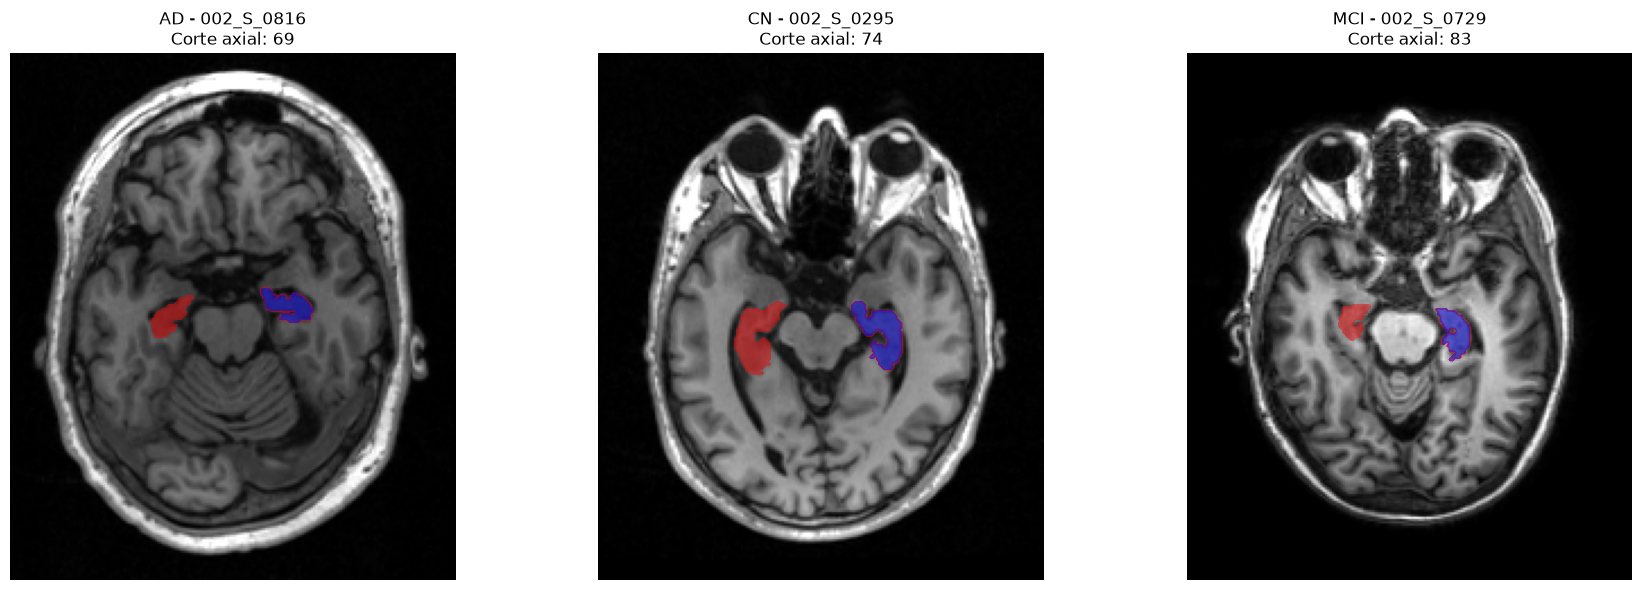

In [14]:
grupos = ["ad", "cn", "mci"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, grupo in zip(axes, grupos):

    # Selecionar primeiro exame do grupo
    pasta = harp_path / "samples" / grupo
    arquivos = sorted(pasta.glob("*.nii.gz"))

    imagem_path = arquivos[0]
    id_paciente = imagem_path.name.replace(".nii.gz", "")

    # Carregar imagem e máscara bilateral alinhada
    imagem = nib.load(str(imagem_path)).get_fdata()

    mascara_path = (harp_path / "masks" / "multiclass_aligned" / f"{id_paciente}.nii.gz")

    mascara = nib.load(str(mascara_path)).get_fdata()

    # Encontrar corte axial com maior quantidade de voxels segmentados
    voxels_por_corte = np.sum(mascara > 0, axis=(0, 1))
    indice_corte = np.argmax(voxels_por_corte)

    # Extrair os cortes
    imagem_corte = imagem[:, :, indice_corte]
    mascara_corte = mascara[:, :, indice_corte]

    # Ajustar contraste da imagem
    valores = imagem_corte[imagem_corte > 0]

    vmin, vmax = np.percentile(valores, [1, 99])

    # Mostrar imagem T1
    ax.imshow(
        imagem_corte.T,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )

    # Sobrepor contorno da máscara
    if np.any(mascara_corte == 1):
        ax.contourf(
            mascara_corte.T,
            levels=[0.5, 1.5],
            colors=["red"],
            alpha=0.45
        )

    if np.any(mascara_corte == 2):
        ax.contourf(
            (mascara_corte == 2).T,
            levels=[0.5, 1.5],
            colors=["blue"],
            alpha=0.45
        )

    ax.set_title(
        f"{grupo.upper()} - {id_paciente}\n"
        f"Corte axial: {indice_corte}"
    )

    ax.axis("off")

plt.tight_layout()
#plt.savefig("exemplo_segmentação_hip.png", dpi=150, bbox_inches="tight")
plt.show()


AD - 002_S_0816
Cortes selecionados: [60, 68, 74, 82, 88]

CN - 002_S_0295
Cortes selecionados: [68, 73, 78, 84, 89]

MCI - 002_S_0729
Cortes selecionados: [76, 82, 86, 92, 96]


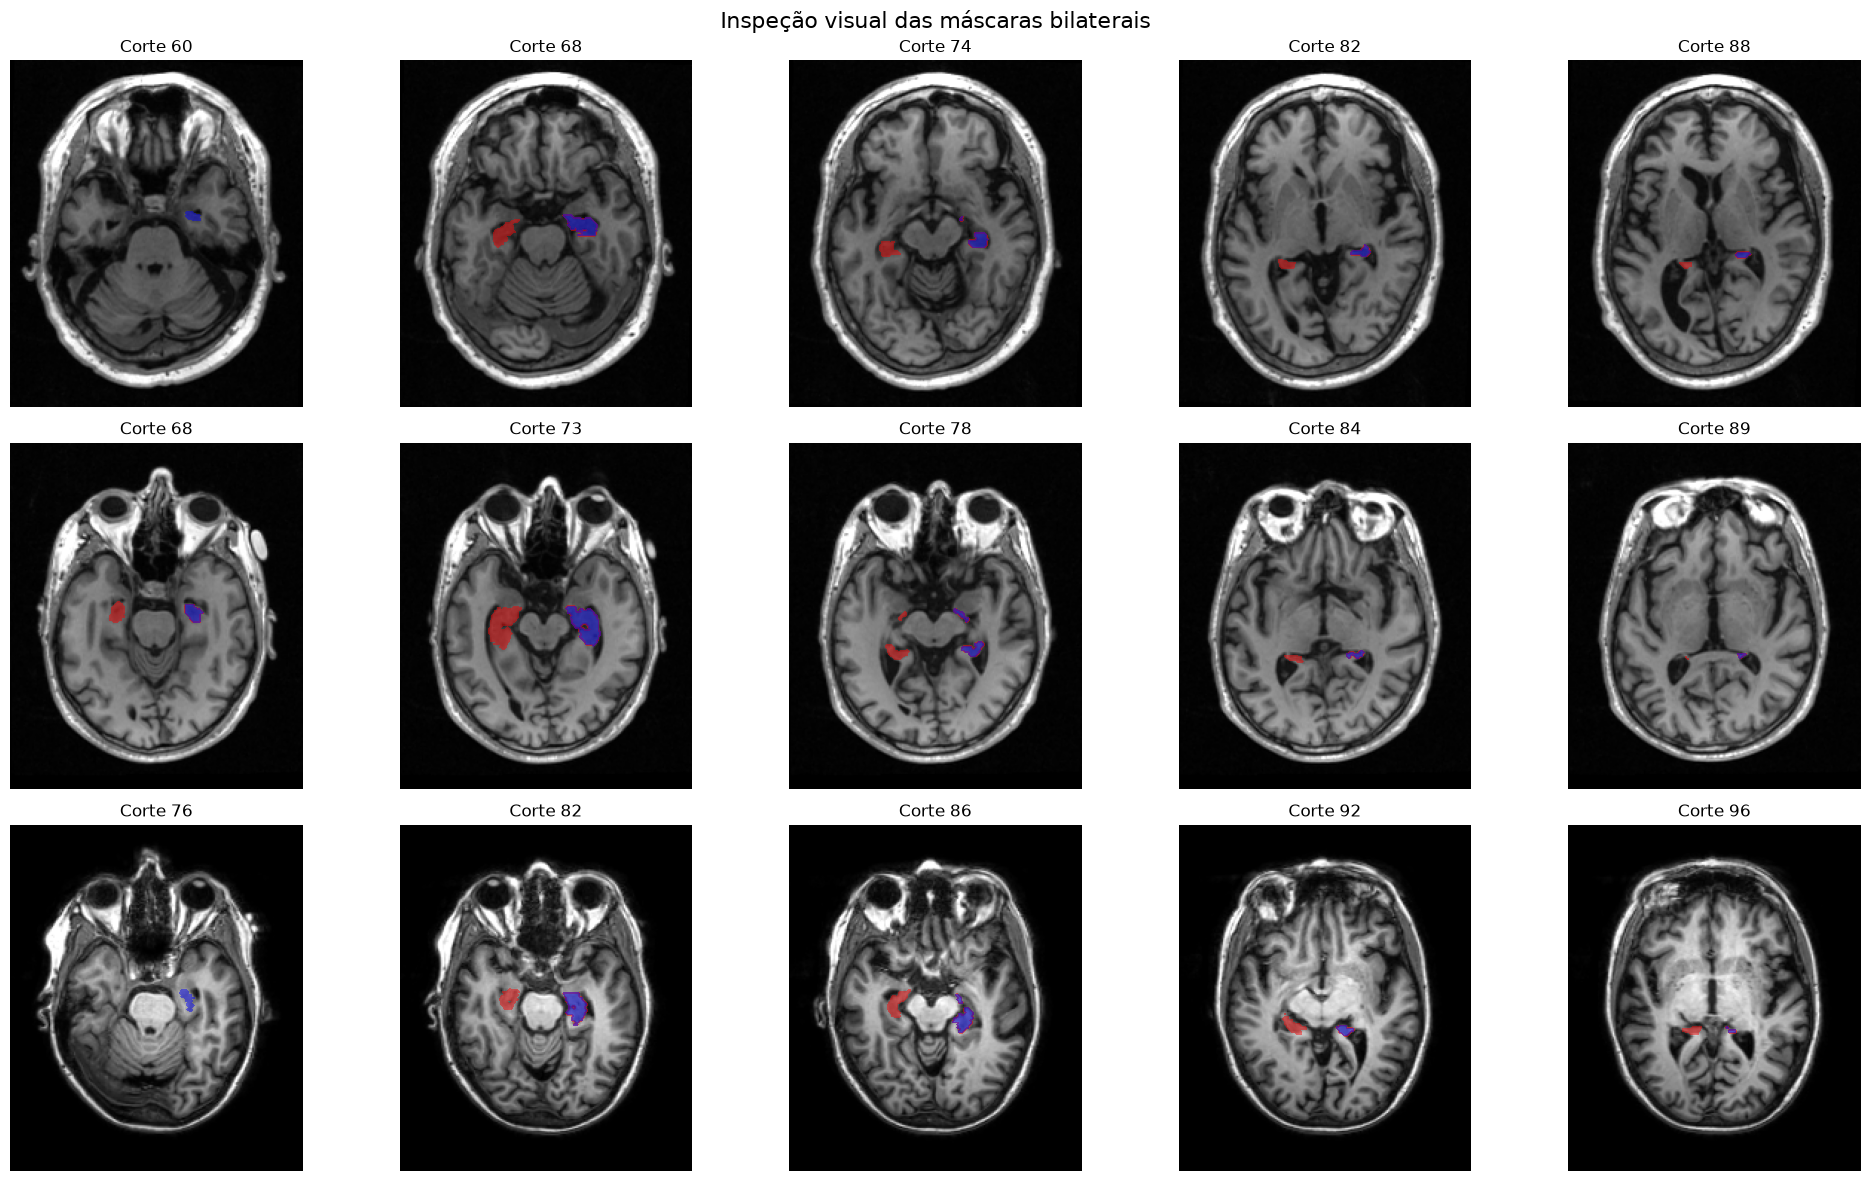

In [15]:
participantes = {
    "AD": "002_S_0816",
    "CN": "002_S_0295",
    "MCI": "002_S_0729"
}

# 3 participantes x 5 cortes axiais
fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for linha, (grupo, id_paciente) in enumerate(participantes.items()):

    # Localizar imagem T1
    imagem_path = (harp_path / "samples" / grupo.lower() / f"{id_paciente}.nii.gz")

    # Localizar máscara bilateral corrigida
    mascara_path = (harp_path / "masks" / "multiclass_aligned" / f"{id_paciente}.nii.gz")

    # Carregar dados
    imagem_nii = nib.load(str(imagem_path))
    mascara_nii = nib.load(str(mascara_path))

    imagem = imagem_nii.get_fdata()
    mascara = mascara_nii.get_fdata()

    # Identificar cortes que possuem voxels segmentados
    voxels_por_corte = np.sum(mascara > 0, axis=(0, 1))

    cortes_validos = np.where(voxels_por_corte > 0)[0]

    # Selecionar cinco cortes distribuídos pela extensão do hipocampo
    quantis = np.linspace(0.1, 0.9, 5)

    cortes = np.quantile(cortes_validos, quantis).round().astype(int)

    # Evitar duplicação de índices
    cortes = np.unique(cortes)

    # Ajustar contraste da imagem
    valores = imagem[imagem > 0]
    vmin, vmax = np.percentile(valores, [1, 99])

    print(f"\n{grupo} - {id_paciente}")
    print("Cortes selecionados:", cortes.tolist())

    for coluna, indice in enumerate(cortes):
        ax = axes[linha, coluna]

        imagem_corte = imagem[:, :, indice]
        mascara_corte = mascara[:, :, indice]

        # Exibir imagem T1
        ax.imshow(
            imagem_corte.T,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        # Sobrepor contorno da máscara
        if np.any(mascara_corte == 1):
            ax.contourf(
                mascara_corte.T,
                levels=[0.5, 1.5],
                colors=["red"],
                alpha=0.45
            )

        if np.any(mascara_corte == 2):
            ax.contourf(
                (mascara_corte == 2).T,
                levels=[0.5, 1.5],
                colors=["blue"],
                alpha=0.45
            )

        ax.set_title(f"Corte {indice}")
        ax.axis("off")

    # Identificação do participante
    axes[linha, 0].set_ylabel(
        f"{grupo}\n{id_paciente}",
        fontsize=12,
        rotation=0,
        labelpad=75,
        va="center"
    )

plt.suptitle(
    "Inspeção visual das máscaras bilaterais",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Pré-Processamento

In [16]:
resultados = []

for grupo in grupos:

    pasta = harp_path / "samples" / grupo

    for imagem_path in sorted(pasta.glob("*.nii.gz")):

        paciente = imagem_path.name.replace(".nii.gz", "")

        mascara_L_path = harp_path / "masks" / grupo / f"{paciente}_L.nii.gz"
        mascara_R_path = harp_path / "masks" / grupo / f"{paciente}_R.nii.gz"

        # Carregar os três volumes
        imagem = nib.as_closest_canonical(nib.load(str(imagem_path)))
        mascara_L = nib.as_closest_canonical(nib.load(str(mascara_L_path)))
        mascara_R = nib.as_closest_canonical(nib.load(str(mascara_R_path)))

        # Verificar compatibilidade geométrica
        shape_ok = (imagem.shape == mascara_L.shape == mascara_R.shape)

        affine_ok = (
            np.allclose(imagem.affine, mascara_L.affine)
            and np.allclose(imagem.affine, mascara_R.affine)
        )

        resultados.append({
            "ID": paciente,
            "Grupo": grupo.upper(),
            "Dimensões": imagem.shape,
            "Espaçamento": tuple(np.round(imagem.header.get_zooms()[:3], 3)),
            "Orientação": nib.aff2axcodes(imagem.affine),
            "Máscaras compatíveis": shape_ok and affine_ok
        })

df_auditoria = pd.DataFrame(resultados)

print("Total de exames:", len(df_auditoria))
print(df_auditoria["Dimensões"].value_counts())
print(df_auditoria["Espaçamento"].value_counts())
print(df_auditoria["Orientação"].value_counts())
print(df_auditoria["Máscaras compatíveis"].value_counts())
display(df_auditoria)

Total de exames: 135
Dimensões
(197, 233, 189)    135
Name: count, dtype: int64
Espaçamento
(1.0, 1.0, 1.0)    135
Name: count, dtype: int64
Orientação
(R, A, S)    135
Name: count, dtype: int64
Máscaras compatíveis
True    135
Name: count, dtype: int64


,ID,Grupo,Dimensões,Espaçamento,Orientação,Máscaras compatíveis
0,002_S_0816,AD,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
1,002_S_0938,AD,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
2,003_S_1059,AD,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
3,003_S_1257,AD,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
4,003_S_4136,AD,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
...,...,...,...,...,...,...
130,127_S_0397,MCI,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
131,131_S_0384,MCI,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
132,131_S_1389,MCI,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True
133,136_S_0429,MCI,"(197, 233, 189)","(1.0, 1.0, 1.0)","(R, A, S)",True


In [17]:
work_dir = harp_path / "baseline_unet_3d"
preprocessed_dir = work_dir / "preprocessed"
images_dir = preprocessed_dir / "images"
labels_dir = preprocessed_dir / "labels"
split_csv = work_dir / "splits.csv"

for folder in [work_dir, preprocessed_dir, images_dir, labels_dir]:
    folder.mkdir(parents=True, exist_ok=True)

print("Diretório de trabalho:", work_dir)

Diretório de trabalho: /mnt/nas/silvana/baseline_unet_3d


In [18]:
records = []

for grupo in grupos:
    pasta = harp_path / "samples" / grupo
    for image_path in sorted(pasta.glob("*.nii.gz")):
        id_paciente = image_path.name.replace(".nii.gz", "")
        masc = harp_path / "masks" / "multiclass_aligned" / f"{id_paciente}.nii.gz"
        masc_esq = harp_path / "masks" / grupo / f"{id_paciente}_L.nii.gz"
        masc_dir = harp_path / "masks" / grupo / f"{id_paciente}_R.nii.gz"

        records.append({
            "ID": id_paciente,
            "Grupo": grupo,
            "Imagem": str(image_path),
            "Máscara Esquerda": str(masc_esq),
            "Máscara Direita": str(masc_dir),
            "Máscara Bilateral": str(masc)
        })

records_df = pd.DataFrame(records)

assert len(records_df) == 135, f"Esperados 135 exames; encontrados {len(records_df)}."
assert records_df["ID"].nunique() == len(records_df), "Há IDs repetidos entre grupos."

In [19]:
# Separa 20% pra teste
train_val_df, test_df = train_test_split(
    records_df,
    test_size=0.2,
    random_state=SEED,
    stratify=records_df["Grupo"]
)

# Separa 10% pra validação
# 10% / 80% = 12,5%
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.125,
    random_state=SEED,
    stratify=train_val_df["Grupo"]
)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")

splits_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

splits_df.to_csv(split_csv, index=False)

In [20]:
zscore_transform = NormalizeIntensity(
    nonzero=True, # Calcula média/desvio apenas nos voxels diferentes de zero, e mantém o fundo em zero
    channel_wise=False,
    dtype=np.float32,
)

normalization_report = []
processed = 0

for _, linha in splits_df.iterrows():
    id_paciente = linha["ID"]
    grupo = linha["Grupo"]

    image_nii = nib.as_closest_canonical(nib.load(linha["Imagem"]))
    esquerda_nii = nib.as_closest_canonical(nib.load(linha["Máscara Esquerda"]))
    direita_nii = nib.as_closest_canonical(nib.load(linha["Máscara Direita"]))

    image = image_nii.get_fdata(dtype=np.float32)
    image = np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)
    masc_esq = esquerda_nii.get_fdata() > 0.5
    masc_dir = direita_nii.get_fdata() > 0.5

    # Mapa de rótulos multiclasse
    target = np.zeros(image.shape, dtype=np.uint8)
    target[masc_esq] = 1 # L = 1
    target[masc_dir] = 2 # R = 2

    # Guardar as estatísticas pré-normalização apenas para o relatório
    foreground_before = image != 0
    if not foreground_before.any():
        raise ValueError(f"Foreground vazio após clipping em {id_paciente}.")

    mean_before = float(image[foreground_before].mean())
    std_before = float(image[foreground_before].std())
    if not np.isfinite(std_before) or std_before <= 1e-8:
        raise ValueError(f"Desvio-padrão inválido em {id_paciente}.")

    # Calcula média e desvio no volume não nulo e mantém o fundo em zero
    image = np.asarray(zscore_transform(image), dtype=np.float32)

    # Verificar a normalização usando a máscara do foreground antes do ZScore
    normalized_mean = float(image[foreground_before].mean())
    normalized_std = float(image[foreground_before].std())
    if not np.isfinite(image).all():
        raise ValueError(f"Valores não finitos após Z-score em {id_paciente}.")
    if not np.isclose(normalized_mean, 0.0, atol=1e-4):
        raise ValueError(f"Média Z-score inesperada em {id_paciente}: {normalized_mean}")
    if not np.isclose(normalized_std, 1.0, atol=1e-4):
        raise ValueError(f"Desvio Z-score inesperado em {id_paciente}: {normalized_std}")
    if np.any(image[~foreground_before] != 0):
        raise ValueError(f"O fundo deixou de ser zero em {id_paciente}.")

    # Salvar imagem normalizada e rótulos com affine/header compatíveis
    image_header = image_nii.header.copy()
    image_header.set_data_dtype(np.float32)
    image_out = nib.Nifti1Image(image.astype(np.float32), image_nii.affine, image_header)

    label_header = image_nii.header.copy()
    label_header.set_data_dtype(np.uint8)
    label_out = nib.Nifti1Image(target.astype(np.uint8), image_nii.affine, label_header)

    nib.save(image_out, str(images_dir / f"{id_paciente}.nii.gz"))
    nib.save(label_out, str(labels_dir / f"{id_paciente}.nii.gz"))

    normalization_report.append({
        "ID": id_paciente,
        "Grupo": linha["Grupo"],
        "Split": linha["split"],
        "Shape": str(image.shape),
        "Media_pre_zscore": mean_before,
        "Desvio_padrao_pre_zscore": std_before,
        "Media_zscore_verificacao": normalized_mean,
        "Desvio_zscore_verificacao": normalized_std,
        "Voxels_L": int(masc_esq.sum()),
        "Voxels_R": int(masc_dir.sum()),
    })
    processed += 1

normalization_df = pd.DataFrame(normalization_report)
normalization_df.to_csv(work_dir / "normalization_report.csv", index=False)

print("Exames processados:", processed)
print("Imagens normalizadas:", images_dir)
print("Rótulos:", labels_dir)
print("Relatório:", work_dir / "normalization_report.csv")
assert processed == 135

Exames processados: 135
Imagens normalizadas: /mnt/nas/silvana/baseline_unet_3d/preprocessed/images
Rótulos: /mnt/nas/silvana/baseline_unet_3d/preprocessed/labels
Relatório: /mnt/nas/silvana/baseline_unet_3d/normalization_report.csv


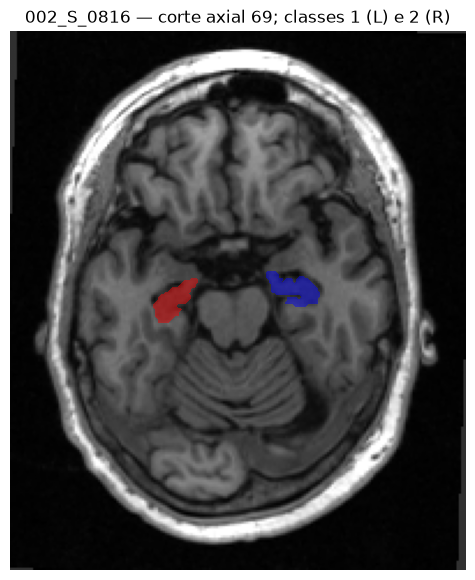

Imagem: (197, 233, 189) -0.8442569971084595 10.726677894592285
Rótulos: (array([0, 1, 2], dtype=uint8), array([8670002,    2482,    2805]))


In [21]:
example_id = "002_S_0816"

img_nii = nib.load(str(images_dir / f"{example_id}.nii.gz"))
lbl_nii = nib.load(str(labels_dir / f"{example_id}.nii.gz"))
img = img_nii.get_fdata(dtype=np.float32)
lbl = lbl_nii.get_fdata().astype(np.uint8)

voxels_per_slice = np.sum(lbl > 0, axis=(0, 1))
z = int(np.argmax(voxels_per_slice))

plt.figure(figsize=(7, 7))
display_values = img[img != 0]
vmin, vmax = np.percentile(display_values, [1, 99])
plt.imshow(img[:, :, z].T, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
plt.contourf((lbl[:, :, z] == 1).T, levels=[0.5, 1.5], colors=["red"], alpha=0.45)
plt.contourf((lbl[:, :, z] == 2).T, levels=[0.5, 1.5], colors=["blue"], alpha=0.45)
plt.title(f"{example_id} — corte axial {z}; classes 1 (L) e 2 (R)")
plt.axis("off")
plt.show()

print("Imagem:", img.shape, float(img.min()), float(img.max()))
print("Rótulos:", np.unique(lbl, return_counts=True))

## Baseline: U-Net 3D

In [22]:
patch_size = (128, 128, 128)

def crop_around_center(image, label, center, patch_size):
    """Extrai patch 3D; faz padding se algum volume for menor que o patch."""
    pad_width = []
    center = np.asarray(center, dtype=int).copy()

    for axis, patch_dim in enumerate(patch_size):
        missing = max(0, patch_dim - image.shape[axis])
        before = missing // 2
        after = missing - before
        pad_width.append((before, after))
        center[axis] += before

    if any(before or after for before, after in pad_width):
        image = np.pad(image, pad_width, mode="constant", constant_values=0)
        label = np.pad(label, pad_width, mode="constant", constant_values=0)

    starts = []
    for axis, patch_dim in enumerate(patch_size):
        start = int(center[axis] - patch_dim // 2)
        start = max(0, min(start, image.shape[axis] - patch_dim))
        starts.append(start)

    slices = tuple(slice(start, start + size) for start, size in zip(starts, patch_size))
    return image[slices], label[slices]


class HarPDataset(Dataset):
    def __init__(self, dataframe, samples_per_volume=2, training=False, patch_size=patch_size, seed=SEED):
        self.records = dataframe.reset_index(drop=True).to_dict("records")
        self.samples_per_volume = samples_per_volume
        self.training = training
        self.patch_size = tuple(patch_size)
        self.rng = np.random.default_rng(seed)
        self.volume_cache = {}

    def __len__(self):
        return len(self.records) * self.samples_per_volume

    def _load_volume(self, volume_index):
        if volume_index in self.volume_cache:
            return self.volume_cache[volume_index]

        id_paciente = self.records[volume_index]["ID"]
        img_nii = nib.load(str(images_dir / f"{id_paciente}.nii.gz"))
        lbl_nii = nib.load(str(labels_dir / f"{id_paciente}.nii.gz"))

        if img_nii.shape != lbl_nii.shape or not np.allclose(img_nii.affine, lbl_nii.affine):
            raise ValueError(f"Imagem/rótulo incompatíveis: {id_paciente}")

        image = img_nii.get_fdata(dtype=np.float32)
        label = lbl_nii.get_fdata().astype(np.uint8)
        coords = {
            1: np.argwhere(label == 1),
            2: np.argwhere(label == 2),
        }
        if len(coords[1]) == 0 or len(coords[2]) == 0:
            raise ValueError(f"Um dos hipocampos está ausente em {id_paciente}.")

        self.volume_cache[volume_index] = (image, label, coords)
        return self.volume_cache[volume_index]

    def __getitem__(self, index):
        volume_index = index // self.samples_per_volume
        patch_index = index % self.samples_per_volume
        image, label, coords = self._load_volume(volume_index)

        if self.training:
            class_id = int(self.rng.choice([1, 2]))
            candidates = coords[class_id]
            center = candidates[self.rng.integers(0, len(candidates))]
        else:
            class_id = 1 if patch_index == 0 else 2
            center = np.round(coords[class_id].mean(axis=0)).astype(int)

        image_patch, label_patch = crop_around_center(
            image, label, center, self.patch_size
        )

        if self.training:
            # Data Augmentation
            scale = self.rng.uniform(0.90, 1.10) # Variação de intensidade ±10%
            shift = self.rng.uniform(-0.05, 0.05) # Deslocamento da intensidade ±0.05
            # Após a normalização os voxels do foreground podem ser negativos.
            foreground_patch = image_patch != 0 # Seleciona voxels não nulos, pois os voxels 0 são do fundo
            augmented = image_patch.copy()
            noise = self.rng.normal(0.0, 0.01, size=image_patch.shape).astype(np.float32) # Adiciona ruído gaussiano com desvio padrão de 0.01
            augmented[foreground_patch] = (image_patch[foreground_patch] * scale + shift + noise[foreground_patch])
            # Preserva o fundo em zero.
            image_patch = augmented

        image_tensor = torch.from_numpy(np.ascontiguousarray(image_patch[None])).float()
        label_tensor = torch.from_numpy(np.ascontiguousarray(label_patch)).long()
        return image_tensor, label_tensor

In [23]:
class HarPDataModule(pl.LightningDataModule):
    def __init__(self, config):
        super().__init__()
        self.config = config

    def setup(self, stage=None):
        split_data = pd.read_csv(split_csv)
        train_df = split_data[split_data["split"] == "train"]
        val_df = split_data[split_data["split"] == "val"]

        self.train_dataset = HarPDataset(
            train_df,
            samples_per_volume=self.config["train_patches_per_volume"],
            training=True,
            patch_size=self.config["patch_size"],
            seed=SEED,
        )
        self.val_dataset = HarPDataset(
            val_df,
            samples_per_volume=2,
            training=False,
            patch_size=self.config["patch_size"],
            seed=SEED,
        )

    def train_dataloader(self):
        return DataLoader(
            self.train_dataset,
            batch_size=self.config["batch_size"],
            shuffle=True,
            num_workers=self.config["num_workers"],
            pin_memory=torch.cuda.is_available(),
        )

    def val_dataloader(self):
        return DataLoader(
            self.val_dataset,
            batch_size=1,
            shuffle=False,
            num_workers=self.config["num_workers"],
            pin_memory=torch.cuda.is_available(),
        )

# Teste rápido de sanidade do DataModule
data_module = HarPDataModule({
    "patch_size": patch_size,
    "batch_size": 2,
    "train_patches_per_volume": 2,
    "num_workers": 0,
})
data_module.setup()

x_batch, y_batch = next(iter(data_module.train_dataloader()))
print("Imagem:", x_batch.shape, x_batch.dtype, float(x_batch.min()), float(x_batch.max()))
print("Rótulo:", y_batch.shape, y_batch.dtype, torch.unique(y_batch))
assert x_batch.shape == (2, 1, *patch_size)
assert y_batch.shape == (2, *patch_size)

Imagem: torch.Size([2, 1, 128, 128, 128]) torch.float32 -0.9355320334434509 6.903268814086914
Rótulo: torch.Size([2, 128, 128, 128]) torch.int64 tensor([0, 1, 2])


In [32]:
class Conv3DBlock(nn.Module):
    def __init__(self, in_channels, out_channels, first_stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, stride=first_stride, padding=1),
            nn.InstanceNorm3d(out_channels, affine=True),
            nn.LeakyReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, stride=1, padding=1),
            nn.InstanceNorm3d(out_channels, affine=True),
            nn.LeakyReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=1, num_classes=3, base_channels=32):
        super().__init__()
        c1 = base_channels          # 32
        c2 = base_channels * 2      # 64
        c3 = base_channels * 4      # 128
        c4 = base_channels * 8      # 256
        c5 = base_channels * 10     # 320
        c6 = base_channels * 10     # 320

        # Encoder
        self.down1 = Conv3DBlock(in_channels, c1, first_stride=1)
        self.down2 = Conv3DBlock(c1, c2, first_stride=2)
        self.down3 = Conv3DBlock(c2, c3, first_stride=2)
        self.down4 = Conv3DBlock(c3, c4, first_stride=2)
        self.down5 = Conv3DBlock(c4, c5, first_stride=2)
        self.down6 = Conv3DBlock(c5, c6, first_stride=2)

        # Decoder
        self.up1 = nn.ConvTranspose3d(c6, c5, kernel_size=2, stride=2)
        self.conv_up1 = Conv3DBlock(c5 + c5, c5, first_stride=1)
        self.up2 = nn.ConvTranspose3d(c5, c4, kernel_size=2, stride=2)
        self.conv_up2 = Conv3DBlock(c4 + c4, c4, first_stride=1)
        self.up3 = nn.ConvTranspose3d(c4, c3, kernel_size=2, stride=2)
        self.conv_up3 = Conv3DBlock(c3 + c3, c3, first_stride=1)
        self.up4 = nn.ConvTranspose3d(c3, c2, kernel_size=2, stride=2)
        self.conv_up4 = Conv3DBlock(c2 + c2, c2, first_stride=1)
        self.up5 = nn.ConvTranspose3d(c2, c1, kernel_size=2, stride=2)
        self.conv_up5 = Conv3DBlock(c1 + c1, c1, first_stride=1)

        # Camada de Saída
        self.outc = nn.Conv3d(c1, num_classes, kernel_size=1)

    @staticmethod
    def _match_size(x, reference):
        # Proteção para diferenças de 1 voxel em entradas com dimensões ímpares.
        # Diferença entre as dimensões de profundidade (d), altura (h) e largura (w)
        diff_d = reference.size(2) - x.size(2)
        diff_h = reference.size(3) - x.size(3)
        diff_w = reference.size(4) - x.size(4)
        if diff_d or diff_h or diff_w:
            # Se houver diferença, faz padding simétrico para igualar as dimensões
            x = F.pad(
                x,
                [diff_w // 2, diff_w - diff_w // 2,
                 diff_h // 2, diff_h - diff_h // 2,
                 diff_d // 2, diff_d - diff_d // 2]
            )
        return x

    # Extrai as características da imagem
    def encode(self, x):
        x1 = self.down1(x)
        x2 = self.down2(x1)
        x3 = self.down3(x2)
        x4 = self.down4(x3)
        x5 = self.down5(x4)
        x6 = self.down6(x5)

        return x1, x2, x3, x4, x5, x6

    # Realiza a decodificação das características e reconstrói a segmentação
    def decode_features(self, features, bottleneck=None):
        x1, x2, x3, x4, x5, x6 = features

        # Se houver bottleneck fornecido, ele substitui o último nível de características extraídas
        x = x6 if bottleneck is None else bottleneck

        x = self.up1(x)
        x = self._match_size(x, x5)
        x = self.conv_up1(torch.cat([x, x5], dim=1))

        x = self.up2(x)
        x = self._match_size(x, x4)
        x = self.conv_up2(torch.cat([x, x4], dim=1))

        x = self.up3(x)
        x = self._match_size(x, x3)
        x = self.conv_up3(torch.cat([x, x3], dim=1))

        x = self.up4(x)
        x = self._match_size(x, x2)
        x = self.conv_up4(torch.cat([x, x2], dim=1))

        x = self.up5(x)
        x = self._match_size(x, x1)
        x = self.conv_up5(torch.cat([x, x1], dim=1))

        return x
    
    def forward(self, x):
        features = self.encode(x)
        decoded = self.decode_features(features)
        return self.outc(decoded)

In [25]:
class DiceCrossEntropyLoss(nn.Module):
    def __init__(self, num_classes=3, dice_weight=0.5):
        super().__init__()
        self.num_classes = num_classes
        self.dice_weight = dice_weight

    def forward(self, logits, target):
        ce = F.cross_entropy(logits, target.long())
        probabilities = torch.softmax(logits, dim=1)
        target_one_hot = F.one_hot(target.long(), num_classes=self.num_classes).permute(0, 4, 1, 2, 3).float()

        dims = (0, 2, 3, 4)
        intersection = (probabilities * target_one_hot).sum(dim=dims)
        denominator = probabilities.sum(dim=dims) + target_one_hot.sum(dim=dims)
        dice_per_class = (2.0 * intersection + 1e-5) / (denominator + 1e-5)
        foreground_dice = dice_per_class[1:].mean()  # ignora o fundo e tira a média sobre o batch e classes
        dice_loss = 1.0 - foreground_dice
        #return (1.0 - self.dice_weight) * ce + self.dice_weight * dice_loss
        return ce + dice_loss


def hard_dice_per_class(logits, target, num_classes=3):
    prediction = torch.argmax(logits, dim=1)
    scores = []
    for class_id in range(1, num_classes):
        pred_class = prediction == class_id
        target_class = target == class_id
        intersection = (pred_class & target_class).sum().float()
        denominator = pred_class.sum().float() + target_class.sum().float()
        score = (2.0 * intersection + 1e-5) / (denominator + 1e-5)
        scores.append(score)
    return torch.stack(scores).mean(), torch.stack(scores)

In [26]:
class LitUNet3D(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.save_hyperparameters({"config": dict(config)})
        self.config = dict(config)
        self.net = UNet3D(
            in_channels=1,
            num_classes=3,
            base_channels=self.config["base_channels"],
        )
        self.loss_fn = DiceCrossEntropyLoss(num_classes=3, dice_weight=0.5)

    def forward(self, x):
        return self.net(x)

    def _shared_step(self, batch, stage):
        image, target = batch
        logits = self(image)
        loss = self.loss_fn(logits, target)
        mean_dice, side_dice = hard_dice_per_class(logits.detach(), target)

        self.log(
            f"{stage}_loss", loss,
            on_step=(stage == "train"), on_epoch=True,
            prog_bar=True, batch_size=image.shape[0]
        )
        self.log(
            f"{stage}_dice", mean_dice,
            on_step=False, on_epoch=True,
            prog_bar=True, batch_size=image.shape[0]
        )
        if stage == "val":
            self.log("val_dice_esquerda", side_dice[0], on_step=False, on_epoch=True, batch_size=1)
            self.log("val_dice_direita", side_dice[1], on_step=False, on_epoch=True, batch_size=1)
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def configure_optimizers(self):
        optimizer = torch.optim.SGD(
            self.net.parameters(),
            lr=self.config["lr"],
            weight_decay=self.config["weight_decay"],
            momentum=self.config["momentum"],
            nesterov=self.config["nesterov"]
        )

        scheduler = torch.optim.lr_scheduler.PolynomialLR(
            optimizer,
            total_iters=self.config["max_epochs"],
            power=0.9
        )
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "monitor": "val_loss",
                "interval": "epoch",
            },
        }


CONFIG = {
    "patch_size": patch_size,
    "base_channels": 32,
    "batch_size": 2,
    "train_patches_per_volume": 2,
    "num_workers": 0,
    "max_epochs": 250,
    "lr": 1e-2,
    "weight_decay": 3e-5,
    "momentum": 0.99,
    "nesterov": True,
    "accumulate_grad_batches": 1,
    "gradient_clip_val": 12.0,
    "precision": "16-mixed" if torch.cuda.is_available() else "32-true",
}

print("Configuração:")
for key, value in CONFIG.items():
    print(f"{key}: {value}")

Configuração:
patch_size: (128, 128, 128)
base_channels: 32
batch_size: 2
train_patches_per_volume: 2
num_workers: 0
max_epochs: 250
lr: 0.01
weight_decay: 3e-05
momentum: 0.99
nesterov: True
accumulate_grad_batches: 1
gradient_clip_val: 12.0
precision: 16-mixed


In [27]:
data_module = HarPDataModule(CONFIG)

model = LitUNet3D(CONFIG)

checkpoint_dir = work_dir / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True, parents=True)

logger = CSVLogger(save_dir=str(work_dir / "logs"), name="unet3d_baseline")

checkpoint_callback = ModelCheckpoint(
    dirpath=str(checkpoint_dir),
    filename="unet3d-{epoch:02d}-{val_dice:.4f}",
    monitor="val_dice",
    mode="max",
    save_top_k=1,
    save_last=True,
)

lr_monitor = LearningRateMonitor(logging_interval="epoch")

# Barra de progresso otimizada (atualização a cada 10 steps)
progress_bar = TQDMProgressBar(refresh_rate=10)

trainer = pl.Trainer(
    max_epochs=CONFIG["max_epochs"],
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    devices=1,
    precision=CONFIG["precision"],
    accumulate_grad_batches=CONFIG["accumulate_grad_batches"],
    gradient_clip_val=CONFIG["gradient_clip_val"],
    logger=logger,
    callbacks=[checkpoint_callback, lr_monitor],
    enable_progress_bar=True,
    log_every_n_steps=5,
    num_sanity_val_steps=2,
)

inicio_treino = time.time()
trainer.fit(model, datamodule=data_module)
tempo_total = time.time() - inicio_treino

horas, resto = divmod(tempo_total, 3600)
minutos, segundos = divmod(resto, 60)

best_checkpoint = checkpoint_callback.best_model_path
print("Melhor checkpoint:", best_checkpoint)
print("Menor val_dice:", checkpoint_callback.best_model_score)
print("Tempo total de treinamento:", f"{int(horas)}h {int(minutos)}m {int(segundos)}s")

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 3060') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /mnt/nas/silvana/baseline_unet_3d/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/silvana/miniconda3/envs

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net     │ UNet3D               │ 31.2 M │ train │     0 │
│ 1 │ loss_fn │ DiceCrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 31.2 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 31.2 M                                                                                               
Total estimated model params size (MB): 124.776                                                                    
Modules in train mode: 96                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connect
or.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value
of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connect
or.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the 
value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

`Trainer.fit` stopped: `max_epochs=250` reached.


Melhor checkpoint: /mnt/nas/silvana/baseline_unet_3d/checkpoints/unet3d-epoch=59-val_dice=0.8320.ckpt
Menor val_dice: tensor(0.8320, device='cuda:0')
Tempo total de treinamento: 4h 13m 55s


## U-Net 3D Multimodal

In [34]:
TEXT_MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
COMMAND_TEXTS = {
    "left": "Segmente o hipocampo esquerdo",
    "right": "Segmente o hipocampo direito",
    "both": "Segmente os dois hipocampos"
}
COMMAND_TARGETS = {"left": 1, "right": 2, "both": "bilateral"}


class HarPCommandDataset(Dataset):
    """Expande cada exame em três pares imagem-comando-máscara."""
    def __init__(self, dataframe, training, samples_per_command=1, seed=SEED):
        self.rows = []
        for row in dataframe.to_dict("records"):
            for command in ("left", "right", "both"):
                item = dict(row)
                item["command"] = command
                self.rows.extend([item] * samples_per_command)
        self.training = training
        self.rng = np.random.default_rng(seed)
        self.cache = {}

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        patient_id = row["ID"]
        if patient_id not in self.cache:
            image_nii = nib.load(str(images_dir / f"{patient_id}.nii.gz"))
            label_nii = nib.load(str(labels_dir / f"{patient_id}.nii.gz"))
            image = image_nii.get_fdata(dtype=np.float32)
            label = label_nii.get_fdata().astype(np.uint8)
            if image.shape != label.shape or not np.allclose(image_nii.affine, label_nii.affine):
                raise ValueError(f"Imagem e máscara desalinhadas: {patient_id}")
            self.cache[patient_id] = (image, label)
        image, label = self.cache[patient_id]

        command = row["command"]
        if command == "left":
            target = (label == 1).astype(np.uint8)
            candidates = np.argwhere(label == 1)
        elif command == "right":
            target = (label == 2).astype(np.uint8)
            candidates = np.argwhere(label == 2)
        else:
            target = (label > 0).astype(np.uint8)
            candidates = np.argwhere(label > 0)

        if len(candidates) == 0:
            raise ValueError(f"Alvo vazio para {patient_id}, comando={command}")
        if self.training:
            center = candidates[self.rng.integers(0, len(candidates))]
        else:
            center = np.round(candidates.mean(axis=0)).astype(int)

        image_patch, target_patch = crop_around_center(
            image, target, center, patch_size
        )

        if self.training:
            scale = self.rng.uniform(0.90, 1.10)
            shift = self.rng.uniform(-0.05, 0.05)
            foreground = image_patch != 0
            augmented = image_patch.copy()
            noise = self.rng.normal(0, 0.01, image_patch.shape).astype(np.float32)
            augmented[foreground] = image_patch[foreground] * scale + shift + noise[foreground]
            image_patch = augmented

        return (
            torch.from_numpy(np.ascontiguousarray(image_patch[None])).float(),
            torch.from_numpy(np.ascontiguousarray(target_patch)).long(),
            command,
        )


class HarPCommandDataModule(pl.LightningDataModule):
    def __init__(self, config):
        super().__init__()
        self.config = config

    def setup(self, stage=None):
        split_data = pd.read_csv(split_csv)
        train_df = split_data[split_data["split"] == "train"]
        val_df = split_data[split_data["split"] == "val"]
        self.train_dataset = HarPCommandDataset(
            train_df, training=True,
            samples_per_command=self.config["train_patches_per_command"],
            seed=SEED,
        )
        self.val_dataset = HarPCommandDataset(val_df, training=False, samples_per_command=1, seed=SEED)

    def train_dataloader(self):
        return DataLoader(
            self.train_dataset, batch_size=self.config["batch_size"],
            shuffle=True, num_workers=self.config["num_workers"],
            pin_memory=torch.cuda.is_available(),
        )

    def val_dataloader(self):
        return DataLoader(
            self.val_dataset, batch_size=1, shuffle=False,
            num_workers=self.config["num_workers"],
            pin_memory=torch.cuda.is_available(),
        )


class CrossAttentionBlock(nn.Module):
    """Cross-attention multi-head com residual e LayerNorm."""
    def __init__(self, embed_dim, num_heads=4, dropout=0.1):
        super().__init__()
        if embed_dim % num_heads:
            raise ValueError("embed_dim deve ser divisível por num_heads.")
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key_value, key_padding_mask=None):
        attended, _ = self.attn(
            query, key_value, key_value,
            key_padding_mask=key_padding_mask,
            need_weights=False,
        )
        return self.norm(query + self.dropout(attended))


class TextConditionedUNet3D(nn.Module):
    def __init__(
        self,
        base_channels=32,
        text_model_name=TEXT_MODEL_NAME,
        freeze_text=True,
        num_heads=4,
        dropout=0.1,
    ):
        super().__init__()
        self.unet = UNet3D(in_channels=1, num_classes=1, base_channels=base_channels)
        self.tokenizer = AutoTokenizer.from_pretrained(text_model_name)
        self.text_encoder = AutoModel.from_pretrained(text_model_name)
        if freeze_text:
            for parameter in self.text_encoder.parameters():
                parameter.requires_grad = False
        self.freeze_text = freeze_text

        bottleneck_channels = base_channels * 10  # c6 da UNet3D
        text_hidden = self.text_encoder.config.hidden_size
        self.text_projection = nn.Sequential(
            nn.Linear(text_hidden, bottleneck_channels),
            nn.LayerNorm(bottleneck_channels),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.text_to_image = CrossAttentionBlock(bottleneck_channels, num_heads=num_heads, dropout=dropout)
        self.image_to_text = CrossAttentionBlock(bottleneck_channels, num_heads=num_heads, dropout=dropout)

    def train(self, mode=True):
        super().train(mode)
        # BERT congelado em eval: desativa dropout do encoder textual.
        if self.freeze_text:
            self.text_encoder.eval()
        return self

    def forward(self, images, commands):
        tokens = self.tokenizer(list(commands), padding=True, truncation=True, max_length=48, return_tensors="pt")
        tokens = {key: value.to(images.device) for key, value in tokens.items()}

        if self.freeze_text:
            with torch.no_grad():
                text_features = self.text_encoder(**tokens).last_hidden_state
        else:
            text_features = self.text_encoder(**tokens).last_hidden_state
        text_features = self.text_projection(text_features)

        features = self.unet.encode(images)
        bottleneck = features[-1]  # [B,C,D,H,W]
        batch, channels, depth, height, width = bottleneck.shape
        image_tokens = bottleneck.flatten(2).transpose(1, 2)

        # SeqCA: texto consulta imagem, e em seguida imagem consulta texto refinado.
        text_refined = self.text_to_image(text_features, image_tokens)
        image_refined = self.image_to_text(
            image_tokens, text_refined,
            key_padding_mask=(tokens["attention_mask"] == 0),
        )

        conditioned_bottleneck = image_refined.transpose(1, 2).reshape(batch, channels, depth, height, width)
        decoder_features = self.unet.decode_features(features, bottleneck=conditioned_bottleneck)
        return self.unet.outc(decoder_features)


class LitTextConditionedUNet3D(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.save_hyperparameters({"config": dict(config)})
        self.config = dict(config)
        self.net = TextConditionedUNet3D(
            base_channels=self.config["base_channels"],
            text_model_name=self.config["text_model_name"],
            freeze_text=self.config["freeze_text"],
            num_heads=self.config["num_heads"],
            dropout=self.config["text_dropout"],
        )
        self.loss_fn = nn.BCEWithLogitsLoss()

    def forward(self, images, commands):
        return self.net(images, commands)

    def _step(self, batch, stage):
        images, targets, commands = batch
        logits = self(images, commands).squeeze(1)
        loss = self.loss_fn(logits, targets.float())
        predictions = torch.sigmoid(logits) >= 0.5
        targets_bool = targets.bool()
        intersection = (predictions & targets_bool).sum(dim=(1, 2, 3)).float()
        denominator = predictions.sum(dim=(1, 2, 3)) + targets_bool.sum(dim=(1, 2, 3))
        dice = ((2 * intersection + 1e-5) / (denominator + 1e-5)).mean()
        self.log(f"{stage}_loss", loss, on_step=(stage == "train"), on_epoch=True,
                 prog_bar=True, batch_size=images.shape[0])
        self.log(f"{stage}_dice", dice, on_step=False, on_epoch=True,
                 prog_bar=True, batch_size=images.shape[0])
        return loss

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._step(batch, "val")

    def configure_optimizers(self):
        optimizer = torch.optim.SGD(
            self.net.parameters(), lr=self.config["lr"],
            weight_decay=self.config["weight_decay"],
            momentum=self.config["momentum"], nesterov=self.config["nesterov"],
        )
        scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=self.config["max_epochs"], power=0.9)
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}


MULTIMODAL_CONFIG = {
    "patch_size": patch_size,
    "base_channels": CONFIG["base_channels"],
    "batch_size": 1,
    "train_patches_per_command": 1,
    "num_workers": CONFIG["num_workers"],
    "max_epochs": CONFIG["max_epochs"],
    "lr": CONFIG["lr"],
    "weight_decay": CONFIG["weight_decay"],
    "momentum": CONFIG["momentum"],
    "nesterov": CONFIG["nesterov"],
    "precision": CONFIG["precision"],
    "text_model_name": TEXT_MODEL_NAME,
    "freeze_text": True,
    "num_heads": 4,
    "text_dropout": 0.1,
}

print("Configuração multimodal:")
for key, value in MULTIMODAL_CONFIG.items():
    print(f"{key}: {value}")

# Teste estrutural com um batch pequeno
multimodal_data = HarPCommandDataModule(MULTIMODAL_CONFIG)
multimodal_data.setup()
xm, ym, cm = next(iter(multimodal_data.train_dataloader()))
print("Imagem:", tuple(xm.shape), "Máscara binária:", tuple(ym.shape), "Comandos:", list(cm))
assert set(torch.unique(ym).tolist()).issubset({0, 1})

multimodal_model = LitTextConditionedUNet3D(MULTIMODAL_CONFIG)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
multimodal_model = multimodal_model.to(device)
with torch.no_grad():
    test_logits = multimodal_model(xm[:1].to(device), [cm[0]])
print("Saída multimodal:", tuple(test_logits.shape))
assert test_logits.shape == (1, 1, *patch_size)
del test_logits, multimodal_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Configuração multimodal:
patch_size: (128, 128, 128)
base_channels: 32
batch_size: 1
train_patches_per_command: 1
num_workers: 0
max_epochs: 250
lr: 0.01
weight_decay: 3e-05
momentum: 0.99
nesterov: True
precision: 16-mixed
text_model_name: neuralmind/bert-base-portuguese-cased
freeze_text: True
num_heads: 4
text_dropout: 0.1
Imagem: (1, 1, 128, 128, 128) Máscara binária: (1, 128, 128, 128) Comandos: ['right']


/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Saída multimodal: (1, 1, 128, 128, 128)


In [ ]:
multimodal_data = HarPCommandDataModule(MULTIMODAL_CONFIG)
multimodal_model = LitTextConditionedUNet3D(MULTIMODAL_CONFIG)

multimodal_checkpoint_dir = work_dir / "checkpoints_multimodal"
multimodal_checkpoint_dir.mkdir(exist_ok=True, parents=True)
multimodal_logger = CSVLogger(save_dir=str(work_dir / "logs"), name="unet3d_text_conditioned")

multimodal_checkpoint_callback = ModelCheckpoint(
    dirpath=str(multimodal_checkpoint_dir),
    filename="unet3d-text-{epoch:02d}-{val_dice:.4f}",
    monitor="val_dice",
    mode="max",
    save_top_k=1,
    save_last=True,
)
multimodal_trainer = pl.Trainer(
    max_epochs=MULTIMODAL_CONFIG["max_epochs"],
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    devices=1,
    precision=MULTIMODAL_CONFIG["precision"],
    gradient_clip_val=CONFIG["gradient_clip_val"],
    accumulate_grad_batches=2,
    logger=multimodal_logger,
    callbacks=[
        multimodal_checkpoint_callback,
        LearningRateMonitor(logging_interval="epoch"),
        TQDMProgressBar(refresh_rate=10),
    ],
    log_every_n_steps=5,
    num_sanity_val_steps=2,
)

inicio_multimodal = time.time()
multimodal_trainer.fit(multimodal_model, datamodule=multimodal_data)
tempo_multimodal = time.time() - inicio_multimodal

horas, resto = divmod(tempo_multimodal, 3600)
minutos, segundos = divmod(resto, 60)

best_multimodal_checkpoint = multimodal_checkpoint_callback.best_model_path
print(f"Tempo de treinamento multimodal:", f"{int(horas)}h {int(minutos)}m {int(segundos)}s")
print("Melhor checkpoint multimodal:", best_multimodal_checkpoint)
print("Melhor Dice de validação:", multimodal_checkpoint_callback.best_model_score)
if not best_multimodal_checkpoint:
    raise RuntimeError("O treinamento multimodal não produziu checkpoint.")

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type                  ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net     │ TextConditionedUNet3D │  141 M │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss     │      0 │ train │     0 │
└───┴─────────┴───────────────────────┴────────┴───────┴───────┘

Trainable params: 32.3 M                                                                                           
Non-trainable params: 108 M                                                                                        
Total params: 141 M                                                                                                
Total estimated model params size (MB): 564.748                                                                    
Modules in train mode: 112                                                                                         
Modules in eval mode: 228                                                                                          
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:538: Found 228 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

# Resultados e Métricas

## Baseline

In [29]:
def sliding_starts(length, patch, overlap=0.5):
    if length <= patch:
        return [0]
    step = max(1, int(round(patch * (1.0 - overlap))))
    starts = list(range(0, length - patch + 1, step))
    last = length - patch
    if starts[-1] != last:
        starts.append(last)
    return starts


@torch.no_grad()
def sliding_window_predict(model, image, patch_size=patch_size, overlap=0.5, device=None):
    """Prediz um volume [X,Y,Z] em patches, acumulando probabilidades na CPU."""
    if device is None:
        device = next(model.parameters()).device

    original_shape = image.shape
    pad_width = [(0, max(0, patch - size)) for size, patch in zip(original_shape, patch_size)]
    padded = np.pad(image, pad_width, mode="constant", constant_values=0)
    padded_shape = padded.shape

    starts_x = sliding_starts(padded_shape[0], patch_size[0], overlap)
    starts_y = sliding_starts(padded_shape[1], patch_size[1], overlap)
    starts_z = sliding_starts(padded_shape[2], patch_size[2], overlap)

    probability_sum = np.zeros((3, *padded_shape), dtype=np.float32)
    count_map = np.zeros(padded_shape, dtype=np.float32)

    model.eval()
    for x0 in starts_x:
        for y0 in starts_y:
            for z0 in starts_z:
                patch = padded[
                    x0:x0 + patch_size[0],
                    y0:y0 + patch_size[1],
                    z0:z0 + patch_size[2]
                ]
                tensor = torch.from_numpy(np.ascontiguousarray(patch[None, None])).float().to(device)
                logits = model(tensor)
                probabilities = torch.softmax(logits, dim=1)[0].float().cpu().numpy()

                sx = slice(x0, x0 + patch_size[0])
                sy = slice(y0, y0 + patch_size[1])
                sz = slice(z0, z0 + patch_size[2])
                probability_sum[:, sx, sy, sz] += probabilities
                count_map[sx, sy, sz] += 1.0

    probability_sum /= np.maximum(count_map[None, ...], 1.0)
    prediction = np.argmax(probability_sum, axis=0).astype(np.uint8)

    crop = tuple(slice(0, size) for size in original_shape)
    return prediction[crop]

def dice_binary(masc_pred, masc_ref):
    """Dice binário. Se ambas vazias retorna 1; se apenas uma vazia retorna 0."""
    masc_pred = np.asarray(masc_pred, dtype=bool)
    masc_ref = np.asarray(masc_ref, dtype=bool)
    denominator = int(masc_pred.sum()) + int(masc_ref.sum())
    if denominator == 0:
        return 1.0
    intersection = np.logical_and(masc_pred, masc_ref).sum()
    return float(2.0 * intersection / denominator)


def hd95_binary(masc_pred, masc_ref, spacing):
    """Hausdorff 95% entre duas máscaras binárias. Se ambas vazias retorna 0; se apenas uma vazia retorna inf."""
    masc_pred = np.asarray(masc_pred, dtype=bool)
    masc_ref = np.asarray(masc_ref, dtype=bool)
    if not masc_pred.any() and not masc_ref.any():
        return 0.0
    if not masc_pred.any() or not masc_ref.any():
        return float("inf")

    structure = np.ones((3, 3, 3), dtype=bool)
    pred_surface = masc_pred ^ binary_erosion(masc_pred, structure=structure, border_value=0)
    ref_surface = masc_ref ^ binary_erosion(masc_ref, structure=structure, border_value=0)

    distance_to_ref = distance_transform_edt(~ref_surface, sampling=spacing)
    distance_to_pred = distance_transform_edt(~pred_surface, sampling=spacing)
    distances = np.concatenate([
        distance_to_ref[pred_surface],
        distance_to_pred[ref_surface],
    ])
    return float(np.percentile(distances, 95))


def relative_volume_error(masc_pred, masc_ref):
    """Erro volumétrico relativo absoluto em porcentagem"""
    pred_volume = int(np.asarray(masc_pred, dtype=bool).sum())
    ref_volume = int(np.asarray(masc_ref, dtype=bool).sum())
    if ref_volume == 0:
        return 0.0 if pred_volume == 0 else float("inf")
    return float(abs(pred_volume - ref_volume) / ref_volume * 100.0)


def calculate_region_metrics(prediction, target, region, spacing):
    """região: 1 = esquerda, 2 = direita, 'bilateral'= ambos."""
    if region == "bilateral":
        masc_pred = prediction > 0
        masc_ref = target > 0
    else:
        masc_pred = prediction == int(region)
        masc_ref = target == int(region)

    return {
        "Dice": dice_binary(masc_pred, masc_ref),
        "HD95_mm": hd95_binary(masc_pred, masc_ref, spacing),
        "RVE_percent": relative_volume_error(masc_pred, masc_ref),
        "Volume_previsto_voxels": int(masc_pred.sum()),
        "Volume_referencia_voxels": int(masc_ref.sum()),
    }


if not best_checkpoint:
    raise RuntimeError("Nenhum checkpoint foi salvo; confira o treinamento antes da avaliação.")

trained_model = LitUNet3D.load_from_checkpoint(best_checkpoint, config=CONFIG)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trained_model = trained_model.to(device).eval()

split_data = pd.read_csv(split_csv)
test_records = split_data[split_data["split"] == "test"].reset_index(drop=True)

predictions_dir = work_dir / "predictions_test"
predictions_dir.mkdir(parents=True, exist_ok=True)

regions = {"esquerda": 1, "direita": 2, "bilateral": "bilateral"}
test_results = []

for _, linha in test_records.iterrows():
    id_paciente = linha["ID"]
    image_nii = nib.load(str(images_dir / f"{id_paciente}.nii.gz"))
    target_nii = nib.load(str(labels_dir / f"{id_paciente}.nii.gz"))
    image = image_nii.get_fdata(dtype=np.float32)
    target = target_nii.get_fdata().astype(np.uint8)
    spacing = tuple(float(v) for v in image_nii.header.get_zooms()[:3])

    if image.shape != target.shape or not np.allclose(image_nii.affine, target_nii.affine):
        raise ValueError(f"Imagem e rótulo desalinhados em {id_paciente}.")

    prediction = sliding_window_predict(
        trained_model, image, patch_size=CONFIG["patch_size"],
        overlap=0.5, device=device,
    )

    pred_header = image_nii.header.copy()
    pred_header.set_data_dtype(np.uint8)
    pred_nii = nib.Nifti1Image(prediction, image_nii.affine, pred_header)
    nib.save(pred_nii, str(predictions_dir / f"{id_paciente}_prediction.nii.gz"))

    result = {"ID": id_paciente, "Grupo": linha["Grupo"], "Spacing_mm": str(spacing)}
    metrics_by_region = {}
    for region_name, region_id in regions.items():
        metrics = calculate_region_metrics(prediction, target, region_id, spacing)
        metrics_by_region[region_name] = metrics
        for metric_name, value in metrics.items():
            result[f"{metric_name}_{region_name}"] = value

    # Média aritmética dos lados
    for metric_name in ["Dice", "HD95_mm", "RVE_percent"]:
        result[f"{metric_name}_media_lados"] = float(np.mean([
            metrics_by_region["esquerda"][metric_name],
            metrics_by_region["direita"][metric_name],
        ]))

    test_results.append(result)
    print(
        f"{id_paciente} ({linha['Grupo']}) | "
        f"Dice L = {result['Dice_esquerda']:.4f} | "
        f"Dice R = {result['Dice_direita']:.4f} | "
        f"Dice Bilateral = {result['Dice_bilateral']:.4f} | "
        f"HD95 Bilateral = {result['HD95_mm_bilateral']:.2f} mm"
    )

results_df = pd.DataFrame(test_results)
results_df.to_csv(work_dir / "test_metrics.csv", index=False)

metric_columns = [
    "Dice_esquerda", "Dice_direita", "Dice_media_lados", "Dice_bilateral",
    "HD95_mm_esquerda", "HD95_mm_direita", "HD95_mm_media_lados", "HD95_mm_bilateral",
    "RVE_percent_esquerda", "RVE_percent_direita", "RVE_percent_media_lados", "RVE_percent_bilateral",
]
summary_df = results_df.groupby("Grupo")[metric_columns].agg(["mean", "std"])
summary_overall = results_df[metric_columns].agg(["mean", "std"]).T
summary_overall.to_csv(work_dir / "test_metrics_summary.csv")

print("\nResultados individuais:")
display(results_df)
print("\nMédia e desvio-padrão no conjunto de teste:")
display(summary_overall.rename(columns={"mean": "média", "std": "desvio-padrão"}))
print("\nResumo por grupo diagnóstico:")
display(summary_df)
print("\nCSV individual:", work_dir / "test_metrics.csv")
print("CSV resumo:", work_dir / "test_metrics_summary.csv")
print("Predições NIfTI:", predictions_dir)

/home/silvana/miniconda3/envs/harp3d/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


002_S_0413 (cn) | Dice L = 0.7122 | Dice R = 0.5689 | Dice Bilateral = 0.9065 | HD95 Bilateral = 1.00 mm
005_S_1341 (ad) | Dice L = 0.8846 | Dice R = 0.9029 | Dice Bilateral = 0.8944 | HD95 Bilateral = 1.00 mm
020_S_0213 (ad) | Dice L = 0.8115 | Dice R = 0.8448 | Dice Bilateral = 0.8839 | HD95 Bilateral = 1.00 mm
136_S_0429 (mci) | Dice L = 0.0372 | Dice R = 0.0000 | Dice Bilateral = 0.4029 | HD95 Bilateral = 4.58 mm
020_S_1288 (cn) | Dice L = 0.7616 | Dice R = 0.6371 | Dice Bilateral = 0.7751 | HD95 Bilateral = 2.00 mm
003_S_0931 (cn) | Dice L = 0.8596 | Dice R = 0.9095 | Dice Bilateral = 0.8846 | HD95 Bilateral = 1.00 mm
131_S_0691 (ad) | Dice L = 0.7815 | Dice R = 0.8046 | Dice Bilateral = 0.8171 | HD95 Bilateral = 2.24 mm
009_S_0862 (cn) | Dice L = 0.7405 | Dice R = 0.6881 | Dice Bilateral = 0.8555 | HD95 Bilateral = 1.00 mm
019_S_4252 (ad) | Dice L = 0.8139 | Dice R = 0.8728 | Dice Bilateral = 0.8465 | HD95 Bilateral = 1.41 mm
002_S_4225 (cn) | Dice L = 0.8188 | Dice R = 0.8058 | 

,ID,Grupo,Spacing_mm,Dice_esquerda,HD95_mm_esquerda,RVE_percent_esquerda,Volume_previsto_voxels_esquerda,Volume_referencia_voxels_esquerda,Dice_direita,HD95_mm_direita,...,Volume_previsto_voxels_direita,Volume_referencia_voxels_direita,Dice_bilateral,HD95_mm_bilateral,RVE_percent_bilateral,Volume_previsto_voxels_bilateral,Volume_referencia_voxels_bilateral,Dice_media_lados,HD95_mm_media_lados,RVE_percent_media_lados
0,002_S_0413,cn,"(1.0, 1.0, 1.0)",0.712245,46.430593,45.280571,4479,3083,0.568928,3.741657,...,1383,3187,0.906528,1.000000,6.507177,5862,6270,0.640587,25.086125,50.942764
1,005_S_1341,ad,"(1.0, 1.0, 1.0)",0.884590,1.000000,2.658855,2278,2219,0.902853,1.000000,...,2623,2565,0.894373,1.000000,2.445652,4901,4784,0.893721,1.000000,2.460032
2,020_S_0213,ad,"(1.0, 1.0, 1.0)",0.811497,151.815348,18.767954,3721,3133,0.844833,1.414214,...,2894,3512,0.883861,1.000000,0.451467,6615,6645,0.828165,76.614781,18.182382
3,136_S_0429,mci,"(1.0, 1.0, 1.0)",0.037160,50.008999,8.300634,3038,3313,0.000000,42.147358,...,2227,2968,0.402910,4.582576,16.175768,5265,6281,0.018580,46.078179,16.633471
4,020_S_1288,cn,"(1.0, 1.0, 1.0)",0.761614,45.609750,4.303220,3358,3509,0.637134,3.741657,...,1988,3791,0.775107,2.000000,26.767123,5346,7300,0.699374,24.675703,25.931615
5,003_S_0931,cn,"(1.0, 1.0, 1.0)",0.859620,164.498021,12.089202,2865,2556,0.909491,1.000000,...,2841,2606,0.884615,1.000000,10.538551,5706,5162,0.884556,82.749011,10.553427
6,131_S_0691,ad,"(1.0, 1.0, 1.0)",0.781492,150.503782,15.917782,2425,2092,0.804579,1.414214,...,1788,1968,0.817116,2.236068,3.768473,4213,4060,0.793036,75.958998,12.532062
7,009_S_0862,cn,"(1.0, 1.0, 1.0)",0.740519,46.368092,31.944444,2850,2160,0.688132,2.236068,...,1659,2689,0.855525,1.000000,7.011755,4509,4849,0.714326,24.302080,35.124323
8,019_S_4252,ad,"(1.0, 1.0, 1.0)",0.813869,1.414214,13.876759,1775,2061,0.872840,1.000000,...,2142,2372,0.846467,1.414214,11.639973,3917,4433,0.843354,1.207107,11.786609
9,002_S_4225,cn,"(1.0, 1.0, 1.0)",0.818783,2.236068,13.840744,3430,3981,0.805815,2.000000,...,2974,3973,0.827553,2.000000,19.487051,6404,7954,0.812299,2.118034,19.492735



Média e desvio-padrão no conjunto de teste:


,média,desvio-padrão
Dice_esquerda,0.710662,0.200976
Dice_direita,0.710735,0.234013
Dice_media_lados,0.710699,0.213450
Dice_bilateral,0.805552,0.123558
HD95_mm_esquerda,74.049383,65.441028
HD95_mm_direita,5.093805,11.039849
HD95_mm_media_lados,39.571594,32.547747
HD95_mm_bilateral,32.775732,61.879050
RVE_percent_esquerda,24.451041,23.383481
RVE_percent_direita,25.027794,18.050498



Resumo por grupo diagnóstico:


Dice_esquerda           Dice_direita           Dice_media_lados  \
               mean       std         mean       std             mean   
Grupo                                                                   
ad         0.756125  0.102706     0.779784  0.110205         0.767954   
cn         0.724373  0.231202     0.678231  0.277695         0.701302   
mci        0.651487  0.246564     0.674192  0.284012         0.662839   

                Dice_bilateral           HD95_mm_esquerda             ...  \
            std           mean       std             mean        std  ...   
Grupo                                                                 ...   
ad     0.099805       0.830172  0.065144        82.447692  77.768238  ...   
cn     0.253154       0.809441  0.141715        63.153507  62.035331  ...   
mci    0.260117       0.777043  0.153872        76.546951  61.660439  ...   

      HD95_mm_bilateral            RVE_percent_esquerda             \
                   mean        std                 mean        std   
Grupo                                                                
ad            38.459592  73.663795            24.829591  19.524139   
cn             8.367682  20.165215            17.561060  14.208771   
mci           51.499922  74.231581            30.962471  33.056188   

      RVE_percent_direita            RVE_percent_media_lados             \
                     mean        std                    mean        std   
Grupo                                                                     
ad              21.649086  18.093664               23.239339  18.178580   
cn              28.862373  18.708985               23.211717  14.255835   
mci             24.571923  18.758767               27.767197  20.000438   

      RVE_percent_bilateral             
                       mean        std  
Grupo                                   
ad                 5.298345   4.160035  
cn                11.734859   8.067092  
mci               15.962166  11.830114  

[3 rows x 24 columns]


CSV individual: /mnt/nas/silvana/baseline_unet_3d/test_metrics.csv
CSV resumo: /mnt/nas/silvana/baseline_unet_3d/test_metrics_summary.csv
Predições NIfTI: /mnt/nas/silvana/baseline_unet_3d/predictions_test


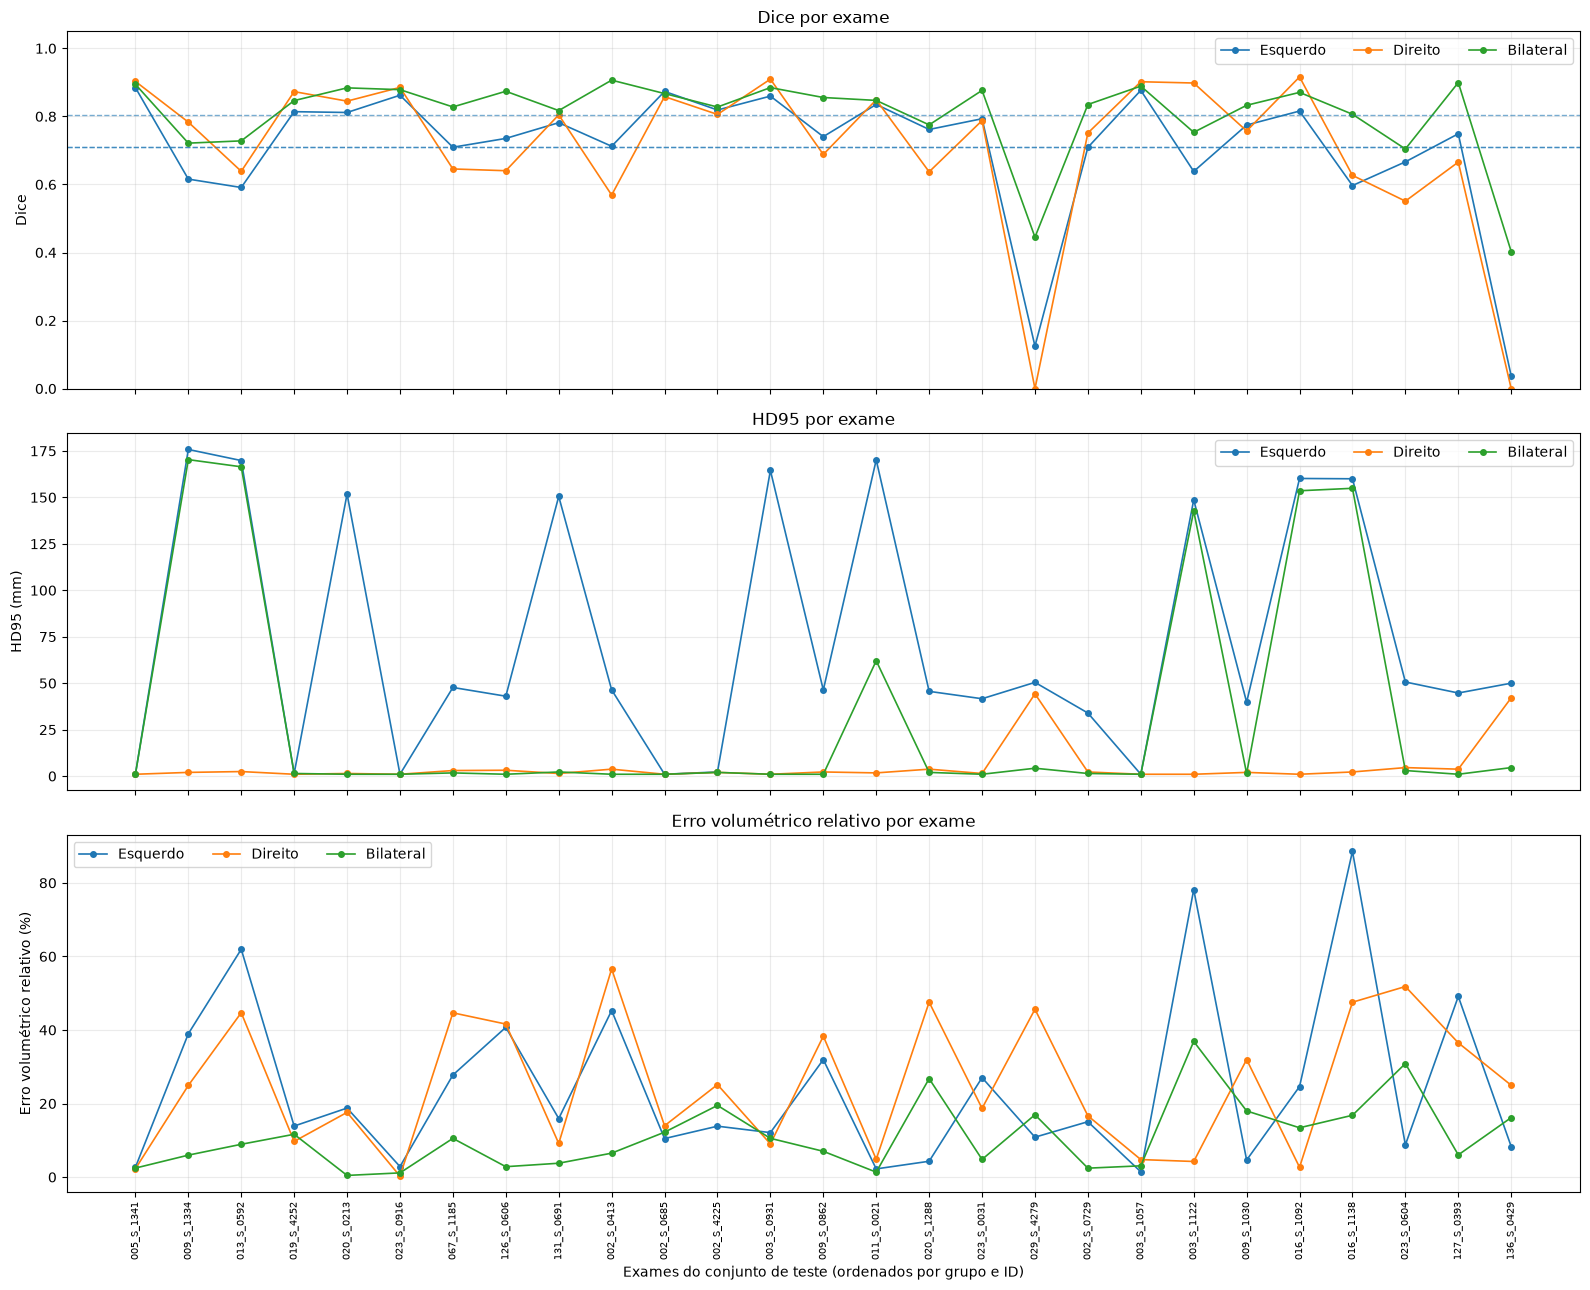

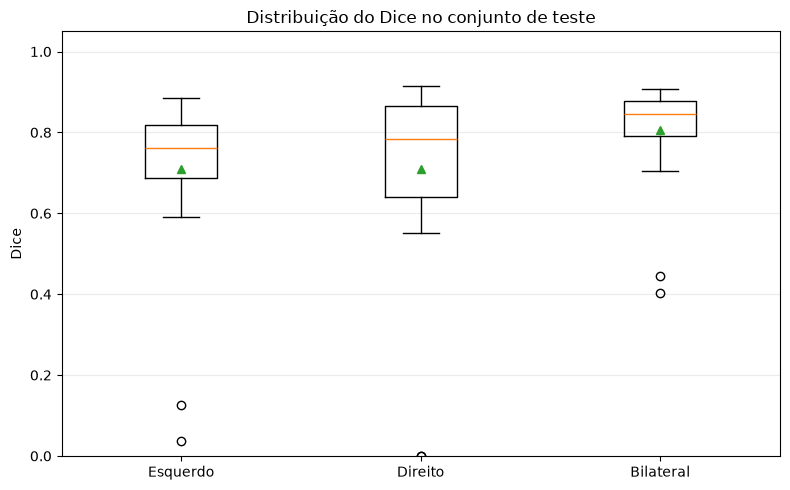

In [30]:
plot_df = results_df.sort_values(["Grupo", "ID"]).reset_index(drop=True)
x = np.arange(len(plot_df))

fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)

# Dice: maior é melhor.
for col, label in [
    ("Dice_esquerda", "Esquerdo"),
    ("Dice_direita", "Direito"),
    ("Dice_bilateral", "Bilateral"),
]:
    axes[0].plot(x, plot_df[col], marker="o", linewidth=1.2, markersize=4, label=label)
    axes[0].axhline(plot_df[col].mean(), linestyle="--", linewidth=1, alpha=0.6)
axes[0].set_ylabel("Dice")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Dice por exame")
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.25)

# HD95: menor é melhor. Infinitos são mostrados no DataFrame, mas omitidos da linha.
for col, label in [
    ("HD95_mm_esquerda", "Esquerdo"),
    ("HD95_mm_direita", "Direito"),
    ("HD95_mm_bilateral", "Bilateral"),
]:
    values = plot_df[col].replace([np.inf, -np.inf], np.nan)
    axes[1].plot(x, values, marker="o", linewidth=1.2, markersize=4, label=label)
axes[1].set_ylabel("HD95 (mm)")
axes[1].set_title("HD95 por exame")
axes[1].legend(ncol=3)
axes[1].grid(alpha=0.25)

# Erro volumétrico relativo: menor é melhor.
for col, label in [
    ("RVE_percent_esquerda", "Esquerdo"),
    ("RVE_percent_direita", "Direito"),
    ("RVE_percent_bilateral", "Bilateral"),
]:
    values = plot_df[col].replace([np.inf, -np.inf], np.nan)
    axes[2].plot(x, values, marker="o", linewidth=1.2, markersize=4, label=label)
axes[2].set_ylabel("Erro volumétrico relativo (%)")
axes[2].set_title("Erro volumétrico relativo por exame")
axes[2].legend(ncol=3)
axes[2].grid(alpha=0.25)

axes[2].set_xticks(x)
axes[2].set_xticklabels(plot_df["ID"], rotation=90, fontsize=7)
axes[2].set_xlabel("Exames do conjunto de teste (ordenados por grupo e ID)")
plt.tight_layout()
plt.show()

# Distribuição do Dice por lado e bilateral.
dice_data = [
    results_df["Dice_esquerda"].dropna(),
    results_df["Dice_direita"].dropna(),
    results_df["Dice_bilateral"].dropna(),
]
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(dice_data, tick_labels=["Esquerdo", "Direito", "Bilateral"], showmeans=True)
ax.set_ylabel("Dice")
ax.set_title("Distribuição do Dice no conjunto de teste")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

/tmp/ipykernel_642083/3673445184.py:20: UserWarning: linewidths is ignored by contourf
  axes[1].contourf((tgt[:, :, z] == 1).T, levels=[0.5, 1.5], linewidths=1.2, colors='red', alpha=0.45)
/tmp/ipykernel_642083/3673445184.py:21: UserWarning: linewidths is ignored by contourf
  axes[1].contourf((tgt[:, :, z] == 2).T, levels=[0.5, 1.5], linewidths=1.2, colors='blue', alpha=0.45)
/tmp/ipykernel_642083/3673445184.py:24: UserWarning: linewidths is ignored by contourf
  axes[2].contourf((pred[:, :, z] == 1).T, levels=[0.5, 1.5], linewidths=1.2, colors='red', alpha=0.45)
/tmp/ipykernel_642083/3673445184.py:25: UserWarning: linewidths is ignored by contourf
  axes[2].contourf((pred[:, :, z] == 2).T, levels=[0.5, 1.5], linewidths=1.2, colors='blue', alpha=0.45)


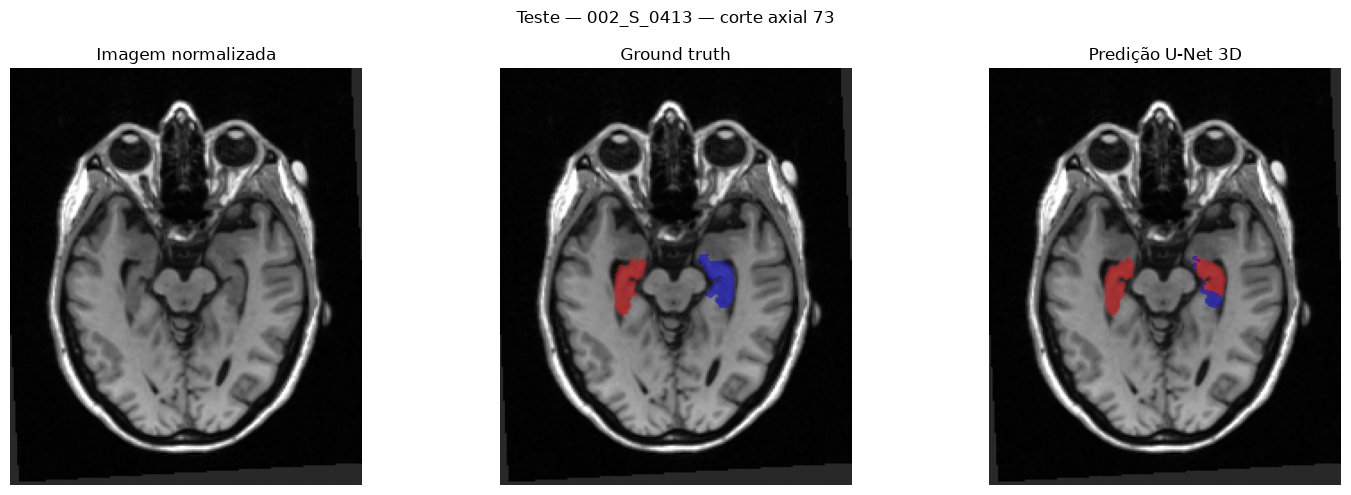

In [31]:
# Selecione o primeiro participante do conjunto de teste.
vis_ID = test_records.iloc[0]["ID"]

img_nii = nib.load(str(images_dir / f"{vis_ID}.nii.gz"))
tgt_nii = nib.load(str(labels_dir / f"{vis_ID}.nii.gz"))
pred_nii = nib.load(str(predictions_dir / f"{vis_ID}_prediction.nii.gz"))

img = img_nii.get_fdata(dtype=np.float32)
tgt = tgt_nii.get_fdata().astype(np.uint8)
pred = pred_nii.get_fdata().astype(np.uint8)

z = int(np.argmax(np.sum(tgt > 0, axis=(0, 1))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
display_values = img[img != 0]
vmin, vmax = np.percentile(display_values, [1, 99])
axes[0].imshow(img[:, :, z].T, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
axes[0].set_title("Imagem normalizada")
axes[1].imshow(img[:, :, z].T, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
axes[1].contourf((tgt[:, :, z] == 1).T, levels=[0.5, 1.5], linewidths=1.2, colors='red', alpha=0.45)
axes[1].contourf((tgt[:, :, z] == 2).T, levels=[0.5, 1.5], linewidths=1.2, colors='blue', alpha=0.45)
axes[1].set_title("Ground truth")
axes[2].imshow(img[:, :, z].T, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
axes[2].contourf((pred[:, :, z] == 1).T, levels=[0.5, 1.5], linewidths=1.2, colors='red', alpha=0.45)
axes[2].contourf((pred[:, :, z] == 2).T, levels=[0.5, 1.5], linewidths=1.2, colors='blue', alpha=0.45)
axes[2].set_title("Predição U-Net 3D")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Teste — {vis_ID} — corte axial {z}")
plt.tight_layout()
plt.show()

## Multimodal

In [ ]:
@torch.no_grad()
def sliding_window_text_predict(model, image, command, patch_size, overlap=0.5, device=None):
    """Inferência binária por janelas deslizantes para um comando textual."""
    if device is None:
        device = next(model.parameters()).device
    original_shape = image.shape
    pad_width = [(0, max(0, p - s)) for s, p in zip(original_shape, patch_size)]
    padded = np.pad(image, pad_width, mode="constant", constant_values=0)
    starts = [sliding_starts(padded.shape[a], patch_size[a], overlap) for a in range(3)]
    probability_sum = np.zeros(padded.shape, dtype=np.float32)
    count_map = np.zeros(padded.shape, dtype=np.float32)
    model.eval()
    for x0 in starts[0]:
        for y0 in starts[1]:
            for z0 in starts[2]:
                patch = padded[x0:x0+patch_size[0], y0:y0+patch_size[1], z0:z0+patch_size[2]]
                tensor = torch.from_numpy(np.ascontiguousarray(patch[None, None])).float().to(device)
                logits = model(tensor, [COMMAND_TEXTS[command]])
                probs = torch.sigmoid(logits[0, 0]).float().cpu().numpy()
                probability_sum[x0:x0+patch_size[0], y0:y0+patch_size[1], z0:z0+patch_size[2]] += probs
                count_map[x0:x0+patch_size[0], y0:y0+patch_size[1], z0:z0+patch_size[2]] += 1
    probability_sum /= np.maximum(count_map, 1)
    crop = tuple(slice(0, size) for size in original_shape)
    return (probability_sum[crop] >= 0.5).astype(np.uint8)


if not best_multimodal_checkpoint:
    raise RuntimeError("Checkpoint multimodal não encontrado. Execute o treinamento primeiro.")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_mm = LitTextConditionedUNet3D.load_from_checkpoint(best_multimodal_checkpoint, config=MULTIMODAL_CONFIG).to(device).eval()

split_data = pd.read_csv(split_csv)
test_records = split_data[split_data["split"] == "test"].reset_index(drop=True)
mm_prediction_dir = work_dir / "predictions_test_multimodal"
mm_prediction_dir.mkdir(parents=True, exist_ok=True)

mm_rows = []
for _, row in test_records.iterrows():
    pid = row["ID"]
    image_nii = nib.load(str(images_dir / f"{pid}.nii.gz"))
    target_nii = nib.load(str(labels_dir / f"{pid}.nii.gz"))
    image = image_nii.get_fdata(dtype=np.float32)
    target = target_nii.get_fdata().astype(np.uint8)
    spacing = tuple(float(v) for v in image_nii.header.get_zooms()[:3])

    if image.shape != target.shape or not np.allclose(image_nii.affine, target_nii.affine):
        raise ValueError(f"Imagem e rótulo desalinhados em {pid}.")

    command_predictions = {}
    for command in ("left", "right", "both"):
        command_predictions[command] = sliding_window_text_predict(
            best_mm, image, command, patch_size=CONFIG["patch_size"],
            overlap=0.5, device=device,
        )
        pred_header = image_nii.header.copy()
        pred_header.set_data_dtype(np.uint8)
        pred_nii = nib.Nifti1Image(command_predictions[command].astype(np.uint8), image_nii.affine, pred_header)
        nib.save(pred_nii, str(mm_prediction_dir / f"{pid}_{command}.nii.gz"))

    result = {"ID": pid, "Grupo": row["Grupo"]}
    # Métricas para comando esquerdo, direito e bilateral.
    for command, target_id in (("left", 1), ("right", 2), ("both", "bilateral")):
        pred = command_predictions[command].astype(bool)
        ref = (target > 0) if target_id == "bilateral" else (target == target_id)
        m = {
            "Dice": dice_binary(pred, ref),
            "HD95_mm": hd95_binary(pred, ref, spacing),
            "RVE_percent": relative_volume_error(pred, ref),
        }
        for metric, value in m.items():
            result[f"{metric}_{command}"] = value

    # Seguimento do comando: previsão unilateral contra lado solicitado e contralateral.
    pred_left = command_predictions["left"].astype(bool)
    pred_right = command_predictions["right"].astype(bool)
    result["Dice_left_command_on_left"] = dice_binary(pred_left, target == 1)
    result["Dice_left_command_on_contralateral"] = dice_binary(pred_left, target == 2)
    result["Dice_right_command_on_right"] = dice_binary(pred_right, target == 2)
    result["Dice_right_command_on_contralateral"] = dice_binary(pred_right, target == 1)
    result["Margin_left_command"] = (result["Dice_left_command_on_left"] - result["Dice_left_command_on_contralateral"])
    result["Margin_right_command"] = (result["Dice_right_command_on_right"] - result["Dice_right_command_on_contralateral"])
    result["Command_swap_margin_mean"] = np.mean([result["Margin_left_command"], result["Margin_right_command"]])

    mm_rows.append(result)
    print(
        f"{pid}: Dice L/R/B = {result['Dice_left']:.3f}/"
        f"{result['Dice_right']:.3f}/{result['Dice_both']:.3f} | "
        f"margens comando L/R = {result['Margin_left_command']:.3f}/"
        f"{result['Margin_right_command']:.3f}"
    )

multimodal_results_df = pd.DataFrame(mm_rows)
multimodal_results_df.to_csv(work_dir / "test_metrics_multimodal.csv", index=False)

summary_cols = [
    "Dice_left", "Dice_right", "Dice_both",
    "HD95_mm_left", "HD95_mm_right", "HD95_mm_both",
    "RVE_percent_left", "RVE_percent_right", "RVE_percent_both",
    "Dice_left_command_on_contralateral",
    "Dice_right_command_on_contralateral",
    "Margin_left_command", "Margin_right_command",
]
summary_multimodal = multimodal_results_df[summary_cols].agg(["mean", "std"]).T
summary_multimodal.columns = ["media", "desvio_padrao"]
summary_multimodal.to_csv(work_dir / "test_metrics_multimodal_summary.csv")

print("\\nResumo no conjunto de teste (média e desvio-padrão):")
display(summary_multimodal)
print("\\nResultados individuais:")
display(multimodal_results_df)
print("CSV multimodal individual:", work_dir / "test_metrics_multimodal.csv")
print("Resumo:", work_dir / "test_metrics_multimodal_summary.csv")
print("Predições por comando:", mm_prediction_dir)

In [ ]:
plot_mm = multimodal_results_df.sort_values(["Grupo", "ID"]).reset_index(drop=True)
x_mm = np.arange(len(plot_mm))

fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)
for col, label in [("Dice_left", "Esquerdo"), ("Dice_right", "Direito"), ("Dice_both", "Bilateral")]:
    axes[0].plot(x_mm, plot_mm[col], marker="o", linewidth=1.2, markersize=4, label=label)
axes[0].set_ylabel("Dice")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Multimodal — Dice por exame e comando")
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.25)

for col, label in [("HD95_mm_left", "Esquerdo"), ("HD95_mm_right", "Direito"), ("HD95_mm_both", "Bilateral")]:
    axes[1].plot(x_mm, plot_mm[col].replace([np.inf, -np.inf], np.nan), marker="o", linewidth=1.2, markersize=4, label=label)
axes[1].set_ylabel("HD95 (mm)")
axes[1].set_title("Multimodal — HD95 por exame e comando")
axes[1].legend(ncol=3)
axes[1].grid(alpha=0.25)

for col, label in [("RVE_percent_left", "Esquerdo"), ("RVE_percent_right", "Direito"), ("RVE_percent_both", "Bilateral")]:
    axes[2].plot(x_mm, plot_mm[col].replace([np.inf, -np.inf], np.nan), marker="o", linewidth=1.2, markersize=4, label=label)
axes[2].set_ylabel("RVE (%)")
axes[2].set_title("Multimodal — erro volumétrico relativo por exame")
axes[2].legend(ncol=3)
axes[2].grid(alpha=0.25)
axes[2].set_xticks(x_mm)
axes[2].set_xticklabels(plot_mm["ID"], rotation=90, fontsize=7)
axes[2].set_xlabel("Exames do conjunto de teste (ordenados por grupo e ID)")
plt.tight_layout()
plt.show()

# Distribuição do Dice multimodal por comando.
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([multimodal_results_df["Dice_left"].dropna(), multimodal_results_df["Dice_right"].dropna(), multimodal_results_df["Dice_both"].dropna()], tick_labels=["Esquerdo", "Direito", "Bilateral"], showmeans=True)
ax.set_ylabel("Dice")
ax.set_title("Multimodal — distribuição do Dice no conjunto de teste")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Seguimento do comando: Dice no lado solicitado versus contralateral.
fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Esquerdo: solicitado", "Esquerdo: contralateral", "Direito: solicitado", "Direito: contralateral"]
values = [multimodal_results_df[c].mean() for c in ["Dice_left_command_on_left", "Dice_left_command_on_contralateral", "Dice_right_command_on_right", "Dice_right_command_on_contralateral"]]
ax.bar(labels, values)
ax.set_ylabel("Dice médio")
ax.set_ylim(0, 1.05)
ax.set_title("Multimodal — seguimento dos comandos unilaterais")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
